# Notebook 10 — Preprocessing Validation and Corrected Models

Objective

To validate the preprocessing workflow used in the Caco-2 permeability study, correct any data leakage caused by fitting preprocessing steps on the complete dataset, and evaluate whether the original model results are affected.

Workflow

1. Load the curated dataset and existing molecular representations.
2. Verify molecular ordering, target alignment, and feature dimensions.
3. Reproduce the original random train/test split.
4. Fit RDKit descriptor scaling using training data only.
5. Rebuild the hybrid representation consistently.
6. Retrain and evaluate the affected Random Forest, XGBoost, and LightGBM models.
7. Validate scaffold-based Random Forest models using training-only preprocessing.
8. Compare corrected results with the original results.
9. Document all changes and identify which manuscript results require updating.

Important: Original notebooks and saved results will remain unchanged. No results will be replaced until the corrected workflow passes validation.

# Import the required libraries

In [2]:
import os
import pickle
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Imports completed successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Imports completed successfully.
NumPy version: 1.26.4
Pandas version: 2.3.3


In [3]:
import os

print(os.listdir())

['.ipynb_checkpoints', '01_DATA', '02_Caco2_Papp_Curated.csv', '02_Data_Set_Audit.ipynb', '03_EDA.ipynb', '04_TDA.ipynb', '05_Chemical_Space_Representation.ipynb', '06_Baseline Prediction Model.ipynb', '07_XGBoost_Representation_Comparison.ipynb', '08_Scaffold-Based_Generalization_Analysis,.ipynb', '08_Scaffold-Based_Generalization_Analysis_02.ipynb', '09_Final Results Consolidation and Publication-Quality Figures.ipynb', '10_Preprocessing Validation and Corrected Models.ipynb', 'Caco2_chemical_space_master.pkl', 'Caco2_chemical_space_primary_results.pkl', 'caco2_morgan_chemical_space.pkl', 'Caco2_Papp_20449_single_fragment_dataset.csv', 'chembl_hia_raw_from_api.csv', 'consolidated_distance_error_correlations.csv', 'consolidated_distance_quintile_endpoints.csv', 'consolidated_model_performance.csv', 'Figure1A_random_split_performance.png', 'Figure1B_scaffold_split_performance.png', 'Figure1_model_performance.png', 'Figure2_distance_error_correlations.png', 'Figure3_Q1_Q5_error_comparis

# Load the dataset and saved representations

In [3]:
df = pd.read_csv("Caco2_Papp_20449_single_fragment_dataset.csv")

with open("RDKit_descriptor_chemical_space.pkl", "rb") as f:
    rdkit_data = pickle.load(f)

with open("Hybrid_chemical_space.pkl", "rb") as f:
    hybrid_data = pickle.load(f)

print("Dataset:", df.shape)
print("RDKit saved object:", type(rdkit_data))
print("Hybrid saved object:", type(hybrid_data))

Dataset: (20449, 15)
RDKit saved object: <class 'dict'>
Hybrid saved object: <class 'dict'>


In [5]:
print("RDKit keys:", rdkit_data.keys())
print("Hybrid keys:", hybrid_data.keys())
print("Dataset columns:", df.columns.tolist())

RDKit keys: dict_keys(['molecules', 'descriptors', 'descriptors_scaled', 'descriptor_names', 'nearest_neighbor_distance'])
Hybrid keys: dict_keys(['molecules', 'morgan_normalized', 'rdkit_normalized', 'hybrid_representation', 'nearest_neighbor_distance', 'nearest_neighbor_index'])
Dataset columns: ['canonical_smiles', 'n_measurements', 'n_assays', 'min_papp', 'max_papp', 'median_papp', 'mean_papp', 'log10_range', 'log10_median_papp', 'mean_median_ratio', 'mol', 'rdkit_canonical_smiles', 'n_fragments', 'parent_mol', 'parent_smiles']


In [6]:
print("RDKit keys:", rdkit_data.keys())
print("Hybrid keys:", hybrid_data.keys())
print("Dataset columns:", df.columns.tolist())

RDKit keys: dict_keys(['molecules', 'descriptors', 'descriptors_scaled', 'descriptor_names', 'nearest_neighbor_distance'])
Hybrid keys: dict_keys(['molecules', 'morgan_normalized', 'rdkit_normalized', 'hybrid_representation', 'nearest_neighbor_distance', 'nearest_neighbor_index'])
Dataset columns: ['canonical_smiles', 'n_measurements', 'n_assays', 'min_papp', 'max_papp', 'median_papp', 'mean_papp', 'log10_range', 'log10_median_papp', 'mean_median_ratio', 'mol', 'rdkit_canonical_smiles', 'n_fragments', 'parent_mol', 'parent_smiles']


# Prepare the common train/test split

In [7]:
# Target variable
y = df["log10_median_papp"].to_numpy()

# One common split for all three representations
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42
)

print("Training molecules:", len(train_idx))
print("Testing molecules:", len(test_idx))

Training molecules: 16359
Testing molecules: 4090


# Correct the RDKit scaling

In [8]:
# Load the original, unscaled RDKit descriptors
X_rdkit = np.asarray(rdkit_data["descriptors"])

# Fit the scaler on training molecules only
scaler_rdkit_corrected = StandardScaler()

X_train_rdkit = scaler_rdkit_corrected.fit_transform(
    X_rdkit[train_idx]
)

# Apply the same scaler to test molecules
X_test_rdkit = scaler_rdkit_corrected.transform(
    X_rdkit[test_idx]
)

print("RDKit training matrix:", X_train_rdkit.shape)
print("RDKit test matrix:", X_test_rdkit.shape)

RDKit training matrix: (16359, 205)
RDKit test matrix: (4090, 205)


# Rebuild the hybrid representation

In [9]:
from sklearn.preprocessing import normalize

# Load original feature blocks
X_morgan = np.asarray(hybrid_data["morgan_normalized"])
X_rdkit_raw = np.asarray(rdkit_data["descriptors"])

# Fit RDKit scaling on training data only
scaler_hybrid = StandardScaler()
X_rdkit_train_scaled = scaler_hybrid.fit_transform(
    X_rdkit_raw[train_idx]
)
X_rdkit_test_scaled = scaler_hybrid.transform(
    X_rdkit_raw[test_idx]
)

# Normalize the Morgan and RDKit blocks separately
X_morgan_train = normalize(X_morgan[train_idx], norm="l2")
X_morgan_test = normalize(X_morgan[test_idx], norm="l2")

X_rdkit_train_norm = normalize(X_rdkit_train_scaled, norm="l2")
X_rdkit_test_norm = normalize(X_rdkit_test_scaled, norm="l2")

# Combine both blocks
X_train_hybrid = np.hstack([X_morgan_train, X_rdkit_train_norm])
X_test_hybrid = np.hstack([X_morgan_test, X_rdkit_test_norm])

print("Hybrid training matrix:", X_train_hybrid.shape)
print("Hybrid test matrix:", X_test_hybrid.shape)

Hybrid training matrix: (16359, 2253)
Hybrid test matrix: (4090, 2253)


In [11]:
morgan_data = pickle.load(
    open("caco2_morgan_chemical_space.pkl", "rb")
)
print(morgan_data.keys())

dict_keys(['df_cs', 'X_morgan', 'nearest_indices', 'nearest_similarities', 'nearest_distances'])


In [13]:
print("RDKit data:", rdkit_data.keys())
print("Hybrid data:", hybrid_data.keys())
print("Morgan data loaded:", "morgan_data" in globals())

RDKit data: dict_keys(['molecules', 'descriptors', 'descriptors_scaled', 'descriptor_names', 'nearest_neighbor_distance'])
Hybrid data: dict_keys(['molecules', 'morgan_normalized', 'rdkit_normalized', 'hybrid_representation', 'nearest_neighbor_distance', 'nearest_neighbor_index'])
Morgan data loaded: True


In [14]:
print("Morgan data type:", type(morgan_data))

if isinstance(morgan_data, dict):
    print("Morgan data keys:", morgan_data.keys())
else:
    print("Morgan data shape:", np.asarray(morgan_data).shape)

Morgan data type: <class 'dict'>
Morgan data keys: dict_keys(['df_cs', 'X_morgan', 'nearest_indices', 'nearest_similarities', 'nearest_distances'])


In [15]:
# Extract Morgan fingerprints
X_morgan_original = np.asarray(morgan_data["X_morgan"])

print("Morgan feature matrix:", X_morgan_original.shape)

# Use the same train/test split as RDKit and Hybrid
X_train_morgan = X_morgan_original[train_idx]
X_test_morgan = X_morgan_original[test_idx]

print("Morgan training matrix:", X_train_morgan.shape)
print("Morgan test matrix:", X_test_morgan.shape)

Morgan feature matrix: (20449, 2048)
Morgan training matrix: (16359, 2048)
Morgan test matrix: (4090, 2048)


# Train the three corrected Random Forest models

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Prepare all feature sets
feature_sets = {
    "Morgan": (X_train_morgan, X_test_morgan),
    "RDKit": (X_train_rdkit, X_test_rdkit),
    "Hybrid": (X_train_hybrid, X_test_hybrid)
}

results = []

for name, (X_train, X_test) in feature_sets.items():
    print(f"Training Random Forest: {name}")

    model = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y[train_idx])
    predictions = model.predict(X_test)

    results.append({
        "Representation": name,
        "MAE": mean_absolute_error(y[test_idx], predictions),
        "RMSE": np.sqrt(mean_squared_error(y[test_idx], predictions)),
        "R2": r2_score(y[test_idx], predictions)
    })

corrected_rf_results = pd.DataFrame(results)
print(corrected_rf_results.round(4).to_string(index=False))

Training Random Forest: Morgan
Training Random Forest: RDKit
Training Random Forest: Hybrid
Representation    MAE   RMSE     R2
        Morgan 0.3853 0.5498 0.5546
         RDKit 0.4044 0.5681 0.5244
        Hybrid 0.3980 0.5598 0.5382


In [17]:
corrected_rf_results.to_csv(
    "corrected_random_forest_results.csv",
    index=False
)

print("Corrected Random Forest results saved.")

Corrected Random Forest results saved.


# XGBoost using the same train/test SPLIT

In [18]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

xgb_results = []

for name, (X_train, X_test) in feature_sets.items():
    print(f"Training XGBoost: {name}")

    model = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y[train_idx])
    predictions = model.predict(X_test)

    xgb_results.append({
        "Representation": name,
        "MAE": mean_absolute_error(y[test_idx], predictions),
        "RMSE": np.sqrt(mean_squared_error(y[test_idx], predictions)),
        "R2": r2_score(y[test_idx], predictions)
    })

corrected_xgb_results = pd.DataFrame(xgb_results)

print("\nCorrected XGBoost results:")
print(corrected_xgb_results.round(4).to_string(index=False))

Training XGBoost: Morgan
Training XGBoost: RDKit
Training XGBoost: Hybrid

Corrected XGBoost results:
Representation    MAE   RMSE     R2
        Morgan 0.4314 0.5821 0.5008
         RDKit 0.4063 0.5569 0.5431
        Hybrid 0.4159 0.5646 0.5302


In [19]:
corrected_xgb_results.to_csv(
    "corrected_xgboost_results.csv",
    index=False
)

print("Corrected XGBoost results saved.")

Corrected XGBoost results saved.


# Train LightGBM

In [21]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

lgbm_results = []

for name, (X_train, X_test) in feature_sets.items():
    print(f"Training LightGBM: {name}")

    model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(X_train, y[train_idx])
    predictions = model.predict(X_test)

    lgbm_results.append({
        "Representation": name,
        "MAE": mean_absolute_error(y[test_idx], predictions),
        "RMSE": np.sqrt(mean_squared_error(y[test_idx], predictions)),
        "R2": r2_score(y[test_idx], predictions)
    })

corrected_lgbm_results = pd.DataFrame(lgbm_results)

print("\nCorrected LightGBM results:")
print(corrected_lgbm_results.round(4).to_string(index=False))

Training LightGBM: Morgan


C:\Users\kiran\anaconda3\envs\chemtox_env\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Training LightGBM: RDKit


C:\Users\kiran\anaconda3\envs\chemtox_env\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Training LightGBM: Hybrid

Corrected LightGBM results:
Representation    MAE   RMSE     R2
        Morgan 0.4244 0.5772 0.5092
         RDKit 0.4128 0.5664 0.5273
        Hybrid 0.4007 0.5524 0.5504


C:\Users\kiran\anaconda3\envs\chemtox_env\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [22]:
corrected_lgbm_results.to_csv(
    "corrected_lightgbm_results.csv",
    index=False
)

print("Corrected LightGBM results saved.")

Corrected LightGBM results saved.


# Consolidate all three models

In [23]:
    corrected_rf_results["Model"] = "Random Forest"
corrected_xgb_results["Model"] = "XGBoost"
corrected_lgbm_results["Model"] = "LightGBM"

all_corrected_results = pd.concat(
    [
        corrected_rf_results,
        corrected_xgb_results,
        corrected_lgbm_results
    ],
    ignore_index=True
)

all_corrected_results = all_corrected_results[
    ["Model", "Representation", "MAE", "RMSE", "R2"]
]

print(all_corrected_results.round(4).to_string(index=False))

all_corrected_results.to_csv(
    "corrected_model_representation_comparison.csv",
    index=False
)

print("\nConsolidated results saved.")

        Model Representation    MAE   RMSE     R2
Random Forest         Morgan 0.3853 0.5498 0.5546
Random Forest          RDKit 0.4044 0.5681 0.5244
Random Forest         Hybrid 0.3980 0.5598 0.5382
      XGBoost         Morgan 0.4314 0.5821 0.5008
      XGBoost          RDKit 0.4063 0.5569 0.5431
      XGBoost         Hybrid 0.4159 0.5646 0.5302
     LightGBM         Morgan 0.4244 0.5772 0.5092
     LightGBM          RDKit 0.4128 0.5664 0.5273
     LightGBM         Hybrid 0.4007 0.5524 0.5504

Consolidated results saved.


# Check the available saved results

In [24]:
import os

files_to_check = [
    "Caco2_chemical_space_primary_results.pkl",
    "caco2_morgan_chemical_space.pkl",
    "RDKit_descriptor_chemical_space.pkl",
    "Hybrid_chemical_space.pkl",
    "corrected_random_forest_results.csv",
    "corrected_xgboost_results.csv",
    "corrected_lightgbm_results.csv",
    "corrected_model_representation_comparison.csv"
]

for filename in files_to_check:
    print(f"{filename}: {'Found' if os.path.exists(filename) else 'Not found'}")

Caco2_chemical_space_primary_results.pkl: Found
caco2_morgan_chemical_space.pkl: Found
RDKit_descriptor_chemical_space.pkl: Found
Hybrid_chemical_space.pkl: Found
corrected_random_forest_results.csv: Found
corrected_xgboost_results.csv: Found
corrected_lightgbm_results.csv: Found
corrected_model_representation_comparison.csv: Found


# Inspect the saved chemical-space results

In [29]:
import pickle

with open("Caco2_chemical_space_primary_results.pkl", "rb") as f:
    primary_results = pickle.load(f)

print("Primary results type:", type(primary_results))

if isinstance(primary_results, dict):
    print("Available keys:")
    for key, value in primary_results.items():
        print(f"{key}: {type(value).__name__}")
else:
    print("Shape:", getattr(primary_results, "shape", "Not applicable"))

Primary results type: <class 'dict'>
Available keys:
n_molecules: int
n_test_molecules: int
Morgan_features: int
RDKit_features: int
Hybrid_features: int
model_performance: dict
distance_error_spearman: dict
q1_q5: dict
friedman_test: dict
pairwise_wilcoxon: dict
standardized_slopes: dict
bootstrap_slope_comparison: dict
outlier_robustness: dict


# Inspect the original distance–error results

In [30]:
print("Original distance-error Spearman correlations:")
print(primary_results["distance_error_spearman"])

print("\nOriginal Q1 vs Q5 results:")
print(primary_results["q1_q5"])

Original distance-error Spearman correlations:
{'Morgan': {'rho': 0.177002, 'p': 3.87793e-30}, 'RDKit': {'rho': 0.250541, 'p': 1.407923e-59}, 'Hybrid': {'rho': 0.188698, 'p': 4.295097e-34}}

Original Q1 vs Q5 results:
{'Morgan': {'Q1_mean_error': 0.3249, 'Q5_mean_error': 0.4878, 'increase_percent': 50.1, 'rank_biserial': 0.2876, 'p': 6.271338e-24}, 'RDKit': {'Q1_mean_error': 0.2964, 'Q5_mean_error': 0.5351, 'increase_percent': 80.6, 'rank_biserial': 0.3549, 'p': 1.854186e-35}, 'Hybrid': {'Q1_mean_error': 0.318, 'Q5_mean_error': 0.5014, 'increase_percent': 57.7, 'rank_biserial': 0.274, 'p': 8.430179e-22}}


# Inspect the saved predictions

In [32]:
print("Primary results keys:")
print(primary_results["model_performance"].keys())

print("\nMorgan data columns:")
print(morgan_data["df_cs"].columns.tolist())

print("\nMorgan nearest-distance shape:")
print(np.asarray(morgan_data["nearest_distances"]).shape)

print("\nRDKit nearest-distance shape:")
print(np.asarray(rdkit_data["nearest_neighbor_distance"]).shape)

print("\nHybrid nearest-distance shape:")
print(np.asarray(hybrid_data["nearest_neighbor_distance"]).shape)

Primary results keys:
dict_keys(['Morgan', 'RDKit', 'Hybrid'])

Morgan data columns:
['canonical_smiles', 'n_measurements', 'n_assays', 'min_papp', 'max_papp', 'median_papp', 'mean_papp', 'log10_range', 'log10_median_papp', 'mean_median_ratio', 'mol', 'rdkit_canonical_smiles', 'n_fragments', 'parent_mol', 'parent_smiles', 'morgan_fp']

Morgan nearest-distance shape:
(20449,)

RDKit nearest-distance shape:
(20449,)

Hybrid nearest-distance shape:
(20449,)


# Inspect the saved model performance data

In [34]:
for representation, results in primary_results["model_performance"].items():
    print(f"\n{representation}")
    print("Type:", type(results))

    if isinstance(results, dict):
        for key, value in results.items():
            print(f"  {key}: {type(value).__name__}")
    else:
        print("Shape:", getattr(results, "shape", "Not applicable"))


Morgan
Type: <class 'dict'>
  MAE: float
  RMSE: float
  R2: float

RDKit
Type: <class 'dict'>
  MAE: float
  RMSE: float
  R2: float

Hybrid
Type: <class 'dict'>
  MAE: float
  RMSE: float
  R2: float


# Generate and save test-set predictions from the trained models
# Note: the models from the earlier training loop were not saved.

In [35]:
print([
    name for name in globals()
    if any(term in name.lower() for term in ["model", "prediction", "pred"])
])

['model', 'predictions']


In [36]:
print("Current model:", type(model))
print("Current predictions shape:", np.asarray(predictions).shape)
print("Test target shape:", y[test_idx].shape)

Current model: <class 'lightgbm.sklearn.LGBMRegressor'>
Current predictions shape: (4090,)
Test target shape: (4090,)


In [37]:
# Save current Hybrid LightGBM test predictions
hybrid_lgbm_predictions = np.asarray(predictions).copy()

hybrid_lgbm_prediction_data = pd.DataFrame({
    "test_index": test_idx,
    "actual": y[test_idx],
    "predicted": hybrid_lgbm_predictions,
    "absolute_error": np.abs(
        y[test_idx] - hybrid_lgbm_predictions
    )
})

hybrid_lgbm_prediction_data.to_csv(
    "corrected_lightgbm_hybrid_predictions.csv",
    index=False
)

print("Saved Hybrid LightGBM test predictions.")
print("Rows:", len(hybrid_lgbm_prediction_data))

Saved Hybrid LightGBM test predictions.
Rows: 4090


# distance between each test molecule and its nearest training molecule for the three representations

In [38]:
from sklearn.neighbors import NearestNeighbors

# 1. RDKit descriptor distances
rdkit_nn = NearestNeighbors(n_neighbors=1, metric="euclidean")
rdkit_nn.fit(X_train_rdkit)

rdkit_train_distances, _ = rdkit_nn.kneighbors(X_test_rdkit)
rdkit_test_distances = rdkit_train_distances.ravel()

# 2. Hybrid representation distances
hybrid_nn = NearestNeighbors(n_neighbors=1, metric="euclidean")
hybrid_nn.fit(X_train_hybrid)

hybrid_train_distances, _ = hybrid_nn.kneighbors(X_test_hybrid)
hybrid_test_distances = hybrid_train_distances.ravel()

print("RDKit distances:", rdkit_test_distances.shape)
print("Hybrid distances:", hybrid_test_distances.shape)
print("Expected test molecules:", len(test_idx))

RDKit distances: (4090,)
Hybrid distances: (4090,)
Expected test molecules: 4090


# Calculate Morgan Tanimoto distances

In [39]:
from rdkit import DataStructs
from scipy.spatial.distance import cdist

# Retrieve Morgan fingerprints in the original dataset order
morgan_fps = morgan_data["df_cs"]["morgan_fp"].tolist()

# Separate training and test fingerprints
train_fps = [morgan_fps[i] for i in train_idx]
test_fps = [morgan_fps[i] for i in test_idx]

# Calculate nearest-training-molecule Tanimoto distance
morgan_test_distances = np.empty(len(test_fps))

for i, fp in enumerate(test_fps):
    similarities = DataStructs.BulkTanimotoSimilarity(fp, train_fps)
    morgan_test_distances[i] = 1 - max(similarities)

print("Morgan distances:", morgan_test_distances.shape)
print("Minimum distance:", morgan_test_distances.min())
print("Maximum distance:", morgan_test_distances.max())

Morgan distances: (4090,)
Minimum distance: 0.0
Maximum distance: 0.8125


# Calculate distance–prediction-error correlations

In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

rf_features = {
    "Morgan": (X_train_morgan, X_test_morgan),
    "RDKit": (X_train_rdkit, X_test_rdkit),
    "Hybrid": (X_train_hybrid, X_test_hybrid)
}

rf_predictions = {}
rf_errors = {}

for name, (X_train, X_test) in rf_features.items():
    rf = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y[train_idx])

    pred = rf.predict(X_test)
    rf_predictions[name] = pred
    rf_errors[name] = np.abs(y[test_idx] - pred)

    print(name, "MAE:", round(mean_absolute_error(y[test_idx], pred), 4))

print("All three prediction sets generated.")

Morgan MAE: 0.3853
RDKit MAE: 0.4044
Hybrid MAE: 0.398
All three prediction sets generated.


# Distance–error correlation and Q1/Q5 comparison

In [43]:
from scipy.stats import spearmanr, mannwhitneyu

distance_sets = {
    "Morgan": morgan_test_distances,
    "RDKit": rdkit_test_distances,
    "Hybrid": hybrid_test_distances
}

results = []
q1_q5_results = []

for name in ["Morgan", "RDKit", "Hybrid"]:
    distances = distance_sets[name]
    errors = rf_errors[name]

    # Spearman correlation
    rho, p_value = spearmanr(distances, errors)

    results.append({
        "Representation": name,
        "Spearman_rho": rho,
        "Spearman_p_value": p_value
    })

    # Lowest- and highest-distance quintiles
    q1_cutoff = np.quantile(distances, 0.20)
    q5_cutoff = np.quantile(distances, 0.80)

    q1_errors = errors[distances <= q1_cutoff]
    q5_errors = errors[distances >= q5_cutoff]

    # Independent-group comparison
    _, q1_q5_p = mannwhitneyu(
        q1_errors, q5_errors, alternative="two-sided"
    )

    q1_q5_results.append({
        "Representation": name,
        "Q1_mean_absolute_error": q1_errors.mean(),
        "Q5_mean_absolute_error": q5_errors.mean(),
        "Error_increase_percent": (
            (q5_errors.mean() - q1_errors.mean())
            / q1_errors.mean() * 100
        ),
        "Q1_n": len(q1_errors),
        "Q5_n": len(q5_errors),
        "Mann_Whitney_p_value": q1_q5_p
    })

correlation_results = pd.DataFrame(results)
q1_q5_results_df = pd.DataFrame(q1_q5_results)

correlation_results.to_csv(
    "corrected_distance_error_correlations.csv", index=False
)
q1_q5_results_df.to_csv(
    "corrected_distance_q1_q5_results.csv", index=False
)

print("DISTANCE–ERROR CORRELATIONS")
display(correlation_results.round(6))

print("\nQ1 vs Q5 ERROR COMPARISON")
display(q1_q5_results_df.round(4))

DISTANCE–ERROR CORRELATIONS


,Representation,Spearman_rho,Spearman_p_value
0,Morgan,0.196453,0.0
1,RDKit,0.265104,0.0
2,Hybrid,0.196295,0.0



Q1 vs Q5 ERROR COMPARISON


,Representation,Q1_mean_absolute_error,Q5_mean_absolute_error,Error_increase_percent,Q1_n,Q5_n,Mann_Whitney_p_value
0,Morgan,0.3169,0.4838,52.6807,818,819,0.0
1,RDKit,0.2786,0.5359,92.3193,818,818,0.0
2,Hybrid,0.3064,0.5128,67.3378,818,818,0.0


In [44]:
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

distance_sets = {
    "Morgan": morgan_test_distances,
    "RDKit": rdkit_test_distances,
    "Hybrid": hybrid_test_distances
}

q1_q5_stats = []

for name, distances in distance_sets.items():
    errors = rf_errors[name]

    q1_cutoff = np.quantile(distances, 0.20)
    q5_cutoff = np.quantile(distances, 0.80)

    q1 = errors[distances <= q1_cutoff]
    q5 = errors[distances >= q5_cutoff]

    test_result = mannwhitneyu(
        q1, q5, alternative="two-sided"
    )

    # Rank-biserial correlation; positive means Q5 tends to have larger errors
    effect_size = 2 * test_result.statistic / (len(q1) * len(q5)) - 1

    q1_q5_stats.append({
        "Representation": name,
        "Q1_n": len(q1),
        "Q5_n": len(q5),
        "Q1_mean_error": q1.mean(),
        "Q5_mean_error": q5.mean(),
        "Error_increase_percent": (q5.mean() - q1.mean()) / q1.mean() * 100,
        "Mann_Whitney_U": test_result.statistic,
        "P_value": test_result.pvalue,
        "Rank_biserial": effect_size
    })

q1_q5_stats_df = pd.DataFrame(q1_q5_stats)

q1_q5_stats_df.to_csv(
    "corrected_q1_q5_statistical_validation.csv",
    index=False
)

display(q1_q5_stats_df.round(8))

,Representation,Q1_n,Q5_n,Q1_mean_error,Q5_mean_error,Error_increase_percent,Mann_Whitney_U,P_value,Rank_biserial
0,Morgan,818,819,0.316897,0.483841,52.680682,235534.0,0.0,-0.296853
1,RDKit,818,818,0.278634,0.535866,92.319322,204097.0,0.0,-0.389958
2,Hybrid,818,818,0.306448,0.512804,67.337805,229550.0,0.0,-0.313879


# Correct the effect-size sign and p-value display

In [45]:
publication_stats = q1_q5_stats_df.copy()

publication_stats["Rank_biserial_Q5_vs_Q1"] = (
    -publication_stats["Rank_biserial"]
)

publication_stats["P_value_scientific"] = (
    publication_stats["P_value"].map(
        lambda p: f"{p:.3e}"
    )
)

display(publication_stats[[
    "Representation",
    "Q1_n",
    "Q5_n",
    "Q1_mean_error",
    "Q5_mean_error",
    "Error_increase_percent",
    "Rank_biserial_Q5_vs_Q1",
    "P_value_scientific"
]].round(4))

publication_stats.to_csv(
    "corrected_q1_q5_publication_stats.csv",
    index=False
)

,Representation,Q1_n,Q5_n,Q1_mean_error,Q5_mean_error,Error_increase_percent,Rank_biserial_Q5_vs_Q1,P_value_scientific
0,Morgan,818,819,0.3169,0.4838,52.6807,0.2969,2.525e-25
1,RDKit,818,818,0.2786,0.5359,92.3193,0.3900,1.874e-42
2,Hybrid,818,818,0.3064,0.5128,67.3378,0.3139,4.207e-28


combines the corrected Random Forest, XGBoost, and LightGBM performance results with the Random Forest distance–error correlations and Q1–Q5 statistics.

In [46]:
import pandas as pd

# Load corrected model performance results
model_results = pd.read_csv(
    "corrected_model_representation_comparison.csv"
)

# Load corrected distance-error correlations
correlation_results = pd.read_csv(
    "corrected_distance_error_correlations.csv"
)

# Load corrected Q1-Q5 statistical results
q1q5_results = pd.read_csv(
    "corrected_q1_q5_publication_stats.csv"
)

# Merge all results by molecular representation
final_results = model_results.merge(
    correlation_results,
    on="Representation",
    how="left"
)

final_results = final_results.merge(
    q1q5_results[[
        "Representation",
        "Q1_n",
        "Q5_n",
        "Q1_mean_error",
        "Q5_mean_error",
        "Error_increase_percent",
        "Rank_biserial_Q5_vs_Q1",
        "P_value_scientific"
    ]],
    on="Representation",
    how="left"
)

# Save the consolidated table
final_results.to_csv(
    "Caco2_corrected_consolidated_results.csv",
    index=False
)

print("Consolidated results saved.")
print("Rows:", len(final_results))
print("Columns:", len(final_results.columns))

display(final_results.round(4))

Consolidated results saved.
Rows: 9
Columns: 14


,Model,Representation,MAE,RMSE,R2,Spearman_rho,Spearman_p_value,Q1_n,Q5_n,Q1_mean_error,Q5_mean_error,Error_increase_percent,Rank_biserial_Q5_vs_Q1,P_value_scientific
0,Random Forest,Morgan,0.3853,0.5498,0.5546,0.1965,0.0,818,819,0.3169,0.4838,52.6807,0.2969,0.0
1,Random Forest,RDKit,0.4044,0.5681,0.5244,0.2651,0.0,818,818,0.2786,0.5359,92.3193,0.3900,0.0
2,Random Forest,Hybrid,0.3980,0.5598,0.5382,0.1963,0.0,818,818,0.3064,0.5128,67.3378,0.3139,0.0
3,XGBoost,Morgan,0.4314,0.5821,0.5008,0.1965,0.0,818,819,0.3169,0.4838,52.6807,0.2969,0.0
4,XGBoost,RDKit,0.4063,0.5569,0.5431,0.2651,0.0,818,818,0.2786,0.5359,92.3193,0.3900,0.0
5,XGBoost,Hybrid,0.4159,0.5646,0.5302,0.1963,0.0,818,818,0.3064,0.5128,67.3378,0.3139,0.0
6,LightGBM,Morgan,0.4244,0.5772,0.5092,0.1965,0.0,818,819,0.3169,0.4838,52.6807,0.2969,0.0
7,LightGBM,RDKit,0.4128,0.5664,0.5273,0.2651,0.0,818,818,0.2786,0.5359,92.3193,0.3900,0.0
8,LightGBM,Hybrid,0.4007,0.5524,0.5504,0.1963,0.0,818,818,0.3064,0.5128,67.3378,0.3139,0.0


# Make the table scientifically clear

In [47]:
performance_table = pd.read_csv(
    "corrected_model_representation_comparison.csv"
)

performance_table.to_csv(
    "Caco2_corrected_model_performance.csv",
    index=False
)

display(performance_table.round(4))

print("Saved: Caco2_corrected_model_performance.csv")
print("Rows:", len(performance_table))

,Model,Representation,MAE,RMSE,R2
0,Random Forest,Morgan,0.3853,0.5498,0.5546
1,Random Forest,RDKit,0.4044,0.5681,0.5244
2,Random Forest,Hybrid,0.3980,0.5598,0.5382
3,XGBoost,Morgan,0.4314,0.5821,0.5008
4,XGBoost,RDKit,0.4063,0.5569,0.5431
5,XGBoost,Hybrid,0.4159,0.5646,0.5302
6,LightGBM,Morgan,0.4244,0.5772,0.5092
7,LightGBM,RDKit,0.4128,0.5664,0.5273
8,LightGBM,Hybrid,0.4007,0.5524,0.5504


Saved: Caco2_corrected_model_performance.csv
Rows: 9


# Save the distance analysis separately

In [48]:
distance_analysis = correlation_results.merge(
    publication_stats[[
        "Representation",
        "Q1_n",
        "Q5_n",
        "Q1_mean_error",
        "Q5_mean_error",
        "Error_increase_percent",
        "Rank_biserial_Q5_vs_Q1",
        "P_value_scientific"
    ]],
    on="Representation",
    how="left"
)

distance_analysis.to_csv(
    "Caco2_corrected_RF_distance_analysis.csv",
    index=False
)

display(distance_analysis.round(4))

print("Saved: Caco2_corrected_RF_distance_analysis.csv")

,Representation,Spearman_rho,Spearman_p_value,Q1_n,Q5_n,Q1_mean_error,Q5_mean_error,Error_increase_percent,Rank_biserial_Q5_vs_Q1,P_value_scientific
0,Morgan,0.1965,0.0,818,819,0.3169,0.4838,52.6807,0.2969,2.525e-25
1,RDKit,0.2651,0.0,818,818,0.2786,0.5359,92.3193,0.3900,1.874e-42
2,Hybrid,0.1963,0.0,818,818,0.3064,0.5128,67.3378,0.3139,4.207e-28


Saved: Caco2_corrected_RF_distance_analysis.csv


# Validate the saved results

In [49]:
import pandas as pd

files_to_check = {
    "Model performance": "Caco2_corrected_model_performance.csv",
    "RF distance analysis": "Caco2_corrected_RF_distance_analysis.csv"
}

for name, filename in files_to_check.items():
    data = pd.read_csv(filename)

    print(f"\n{name}")
    print("File:", filename)
    print("Shape:", data.shape)
    print("Missing values:", data.isna().sum().sum())
    print("Duplicate rows:", data.duplicated().sum())
    print("Columns:", data.columns.tolist())


Model performance
File: Caco2_corrected_model_performance.csv
Shape: (9, 5)
Missing values: 0
Duplicate rows: 0
Columns: ['Model', 'Representation', 'MAE', 'RMSE', 'R2']

RF distance analysis
File: Caco2_corrected_RF_distance_analysis.csv
Shape: (3, 10)
Missing values: 0
Duplicate rows: 0
Columns: ['Representation', 'Spearman_rho', 'Spearman_p_value', 'Q1_n', 'Q5_n', 'Q1_mean_error', 'Q5_mean_error', 'Error_increase_percent', 'Rank_biserial_Q5_vs_Q1', 'P_value_scientific']


In [50]:
import os

scaffold_files = [
    "scaffold_split_predictions.csv",
    "scaffold_training_distance_correlations.csv",
    "scaffold_training_distance_q1q5.csv"
]

for filename in scaffold_files:
    print(filename, "—", "FOUND" if os.path.exists(filename) else "NOT FOUND")

scaffold_split_predictions.csv — FOUND
scaffold_training_distance_correlations.csv — FOUND
scaffold_training_distance_q1q5.csv — FOUND


# Check the scaffold results

In [51]:
import pandas as pd

files = {
    "Scaffold predictions": "scaffold_split_predictions.csv",
    "Scaffold correlations": "scaffold_training_distance_correlations.csv",
    "Scaffold Q1-Q5": "scaffold_training_distance_q1q5.csv"
}

for name, filename in files.items():
    data = pd.read_csv(filename)

    print(f"\n--- {name} ---")
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    display(data.head(5))


--- Scaffold predictions ---
Shape: (4247, 10)
Columns: ['canonical_smiles', 'scaffold', 'log10_median_papp', 'y_true', 'Morgan_pred', 'Morgan_error', 'RDKit_pred', 'RDKit_error', 'Hybrid_pred', 'Hybrid_error']


,canonical_smiles,scaffold,log10_median_papp,y_true,Morgan_pred,Morgan_error,RDKit_pred,RDKit_error,Hybrid_pred,Hybrid_error
0,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1,c1ccc(-c2nc3ccccn3n2)cc1,0.542825,0.542825,1.208765,0.665940,1.187154,0.644328,1.201493,0.658668
1,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,c1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,1.491362,1.491362,1.276727,0.214634,1.249238,0.242124,1.181594,0.309768
2,Brc1ccc2[nH]nc(C3=CCCNC3)c2c1,C1=C(c2n[nH]c3ccccc23)CNCC1,0.897627,0.897627,1.007112,0.109485,0.995471,0.097844,1.011336,0.113709
3,C#CCN(C)CCc1nnn(-c2ccccc2)c1CC,c1ccc(-n2ccnn2)cc1,1.230449,1.230449,1.195823,0.034626,1.121701,0.108748,1.043828,0.186621
4,C#CCN(C)CCc1nnn(-c2ccccc2)c1CCC,c1ccc(-n2ccnn2)cc1,1.235528,1.235528,1.197651,0.037878,1.188944,0.046584,1.058430,0.177098



--- Scaffold correlations ---
Shape: (3, 3)
Columns: ['Representation', 'Spearman_rho', 'p_value']


,Representation,Spearman_rho,p_value
0,Morgan,0.179306,5.109684e-32
1,RDKit,0.211808,2.816861e-44
2,Hybrid,0.146648,7.534988e-22



--- Scaffold Q1-Q5 ---
Shape: (3, 8)
Columns: ['Representation', 'Q1_mean_error', 'Q5_mean_error', 'Increase_percent', 'U_statistic', 'p_value', 'p_holm', 'significant_after_holm']


,Representation,Q1_mean_error,Q5_mean_error,Increase_percent,U_statistic,p_value,p_holm,significant_after_holm
0,Morgan,0.366646,0.557186,51.968178,262164.0,8.848403e-23,1.769681e-22,True
1,RDKit,0.317387,0.562383,77.191689,238174.0,4.976673e-34,1.493002e-33,True
2,Hybrid,0.350675,0.500122,42.616992,274324.0,8.736584e-18,8.736584e-18,True


# Check the scaffold prediction file

In [52]:
scaffold_predictions = pd.read_csv(
    "scaffold_split_predictions.csv"
)

print("Shape:", scaffold_predictions.shape)
print("Columns:", scaffold_predictions.columns.tolist())
display(scaffold_predictions.head())

Shape: (4247, 10)
Columns: ['canonical_smiles', 'scaffold', 'log10_median_papp', 'y_true', 'Morgan_pred', 'Morgan_error', 'RDKit_pred', 'RDKit_error', 'Hybrid_pred', 'Hybrid_error']


,canonical_smiles,scaffold,log10_median_papp,y_true,Morgan_pred,Morgan_error,RDKit_pred,RDKit_error,Hybrid_pred,Hybrid_error
0,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1,c1ccc(-c2nc3ccccn3n2)cc1,0.542825,0.542825,1.208765,0.665940,1.187154,0.644328,1.201493,0.658668
1,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,c1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,1.491362,1.491362,1.276727,0.214634,1.249238,0.242124,1.181594,0.309768
2,Brc1ccc2[nH]nc(C3=CCCNC3)c2c1,C1=C(c2n[nH]c3ccccc23)CNCC1,0.897627,0.897627,1.007112,0.109485,0.995471,0.097844,1.011336,0.113709
3,C#CCN(C)CCc1nnn(-c2ccccc2)c1CC,c1ccc(-n2ccnn2)cc1,1.230449,1.230449,1.195823,0.034626,1.121701,0.108748,1.043828,0.186621
4,C#CCN(C)CCc1nnn(-c2ccccc2)c1CCC,c1ccc(-n2ccnn2)cc1,1.235528,1.235528,1.197651,0.037878,1.188944,0.046584,1.058430,0.177098


# Check the scaffold prediction errors

In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

scaffold_metrics = []

for rep in ["Morgan", "RDKit", "Hybrid"]:
    y_true = scaffold_predictions["y_true"].to_numpy()
    y_pred = scaffold_predictions[f"{rep}_pred"].to_numpy()
    saved_error = scaffold_predictions[f"{rep}_error"].to_numpy()

    scaffold_metrics.append({
        "Representation": rep,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Saved_error_matches": np.allclose(
            saved_error, np.abs(y_true - y_pred)
        )
    })

scaffold_metrics_df = pd.DataFrame(scaffold_metrics)
display(scaffold_metrics_df.round(4))

,Representation,MAE,RMSE,R2,Saved_error_matches
0,Morgan,0.4503,0.6257,0.4495,True
1,RDKit,0.4567,0.6203,0.4590,True
2,Hybrid,0.4513,0.6157,0.4670,True


# Correct the scaffold evaluation

In [54]:
print("Scaffold prediction rows:", len(scaffold_predictions))
print("Unique scaffolds:", scaffold_predictions["scaffold"].nunique())
print("Target column:", "log10_median_papp")
print("Representations:", ["Morgan", "RDKit", "Hybrid"])

Scaffold prediction rows: 4247
Unique scaffolds: 2139
Target column: log10_median_papp
Representations: ['Morgan', 'RDKit', 'Hybrid']


# Check the saved scaffold variables

In [56]:
print("Scaffold-related variables in memory:")

for name in sorted(globals()):
    if "scaffold" in name.lower() or "group" in name.lower():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, "shape:", value.shape)
        elif isinstance(value, (list, tuple, np.ndarray)):
            print(name, "type:", type(value).__name__,
                  "length:", len(value))
        else:
            print(name, "type:", type(value).__name__)

Scaffold-related variables in memory:
GroupShuffleSplit type: ABCMeta
scaffold_files type: list length: 3
scaffold_metrics type: list length: 3
scaffold_metrics_df shape: (3, 5)
scaffold_predictions shape: (4247, 10)


# kernel Restarted

In [4]:
import os

files_to_check = [
    "corrected_model_representation_comparison.csv",
    "corrected_distance_error_correlations.csv",
    "corrected_distance_q1_q5_results.csv",
    "Caco2_corrected_model_performance.csv",
    "Caco2_corrected_RF_distance_analysis.csv"
]

for file in files_to_check:
    print(f"{file}: {'Available' if os.path.exists(file) else 'Missing'}")

corrected_model_representation_comparison.csv: Available
corrected_distance_error_correlations.csv: Available
corrected_distance_q1_q5_results.csv: Available
Caco2_corrected_model_performance.csv: Available
Caco2_corrected_RF_distance_analysis.csv: Available


# Load the saved results

In [5]:
import pandas as pd

model_results = pd.read_csv(
    "Caco2_corrected_model_performance.csv"
)

distance_results = pd.read_csv(
    "Caco2_corrected_RF_distance_analysis.csv"
)

print("Model performance:")
display(model_results)

print("Random Forest distance analysis:")
display(distance_results)

Model performance:


,Model,Representation,MAE,RMSE,R2
0,Random Forest,Morgan,0.385294,0.549837,0.554564
1,Random Forest,RDKit,0.404430,0.568149,0.524400
2,Random Forest,Hybrid,0.397954,0.559845,0.538202
3,XGBoost,Morgan,0.431430,0.582077,0.500796
4,XGBoost,RDKit,0.406337,0.556869,0.543099
5,XGBoost,Hybrid,0.415869,0.564645,0.530248
6,LightGBM,Morgan,0.424442,0.577169,0.509180
7,LightGBM,RDKit,0.412819,0.566428,0.527277
8,LightGBM,Hybrid,0.400701,0.552388,0.550422


Random Forest distance analysis:


,Representation,Spearman_rho,Spearman_p_value,Q1_n,Q5_n,Q1_mean_error,Q5_mean_error,Error_increase_percent,Rank_biserial_Q5_vs_Q1,P_value_scientific
0,Morgan,0.196453,7.278465e-37,818,819,0.316897,0.483841,52.680682,0.296853,2.525000e-25
1,RDKit,0.265104,9.618917e-67,818,818,0.278634,0.535866,92.319322,0.389958,1.874000e-42
2,Hybrid,0.196295,8.311881e-37,818,818,0.306448,0.512804,67.337805,0.313879,4.207000e-28


In [6]:
import os

for folder in [".", "figures", "publication_figures"]:
    if os.path.isdir(folder):
        print(f"\nFolder: {folder}")
        for file in os.listdir(folder):
            if file.lower().endswith((".png", ".jpg", ".jpeg", ".pdf", ".svg")):
                print(file)


Folder: .
Figure1A_random_split_performance.png
Figure1B_scaffold_split_performance.png
Figure1_model_performance.png
Figure2_distance_error_correlations.png
Figure3_Q1_Q5_error_comparison.png
Figure3_Q1_Q5_error_lineplot.png
Figure4_random_vs_scaffold_performance.png


In [7]:
import os
from PIL import Image

for file in os.listdir("."):
    if file.endswith(".png") and file.startswith("Figure"):
        with Image.open(file) as img:
            print(
                f"{file}: {img.size}, "
                f"{os.path.getsize(file) / 1024:.1f} KB"
            )

Figure1A_random_split_performance.png: (4457, 1422), 307.8 KB
Figure1B_scaffold_split_performance.png: (3564, 1334), 230.8 KB
Figure1_model_performance.png: (4756, 1481), 320.9 KB
Figure2_distance_error_correlations.png: (2367, 1468), 100.6 KB
Figure3_Q1_Q5_error_comparison.png: (3267, 1334), 118.8 KB
Figure3_Q1_Q5_error_lineplot.png: (3561, 1422), 279.8 KB
Figure4_random_vs_scaffold_performance.png: (3257, 1422), 187.1 KB


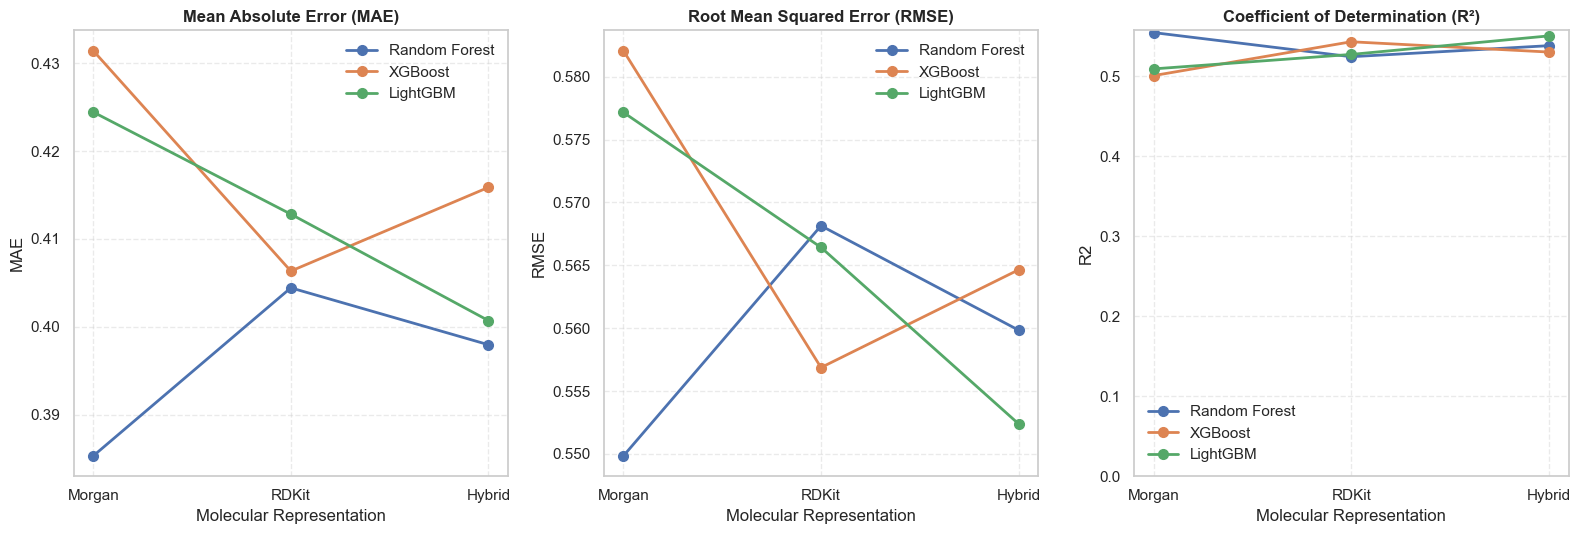

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("Caco2_corrected_model_performance.csv")

metrics = [
    ("MAE", "Mean Absolute Error (MAE)"),
    ("RMSE", "Root Mean Squared Error (RMSE)"),
    ("R2", "Coefficient of Determination (R²)")
]

representations = ["Morgan", "RDKit", "Hybrid"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

for ax, (metric, title) in zip(axes, metrics):
    for model in results["Model"].unique():
        model_data = (
            results[results["Model"] == model]
            .set_index("Representation")
            .reindex(representations)
        )

        ax.plot(
            representations,
            model_data[metric],
            marker="o",
            linewidth=2,
            markersize=7,
            label=model
        )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Molecular Representation")
    ax.set_ylabel(metric)
    ax.grid(True, linestyle="--", alpha=0.4)

    if metric == "R2":
        ax.set_ylim(bottom=0)

    ax.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    "Corrected_Figure1A_Random_Split_Performance_LinePlots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

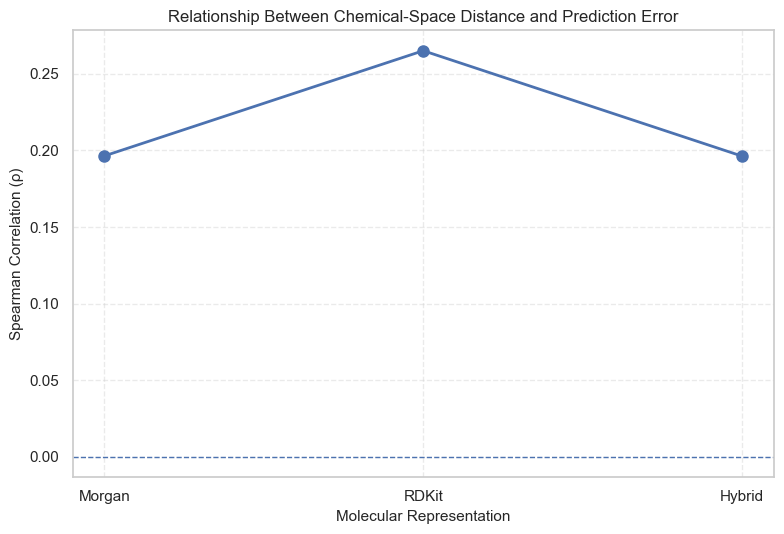

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("Caco2_corrected_RF_distance_analysis.csv")

representations = data["Representation"]
correlations = data["Spearman_rho"]

plt.figure(figsize=(8, 5.5))

plt.plot(
    representations,
    correlations,
    marker="o",
    linewidth=2,
    markersize=8
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Molecular Representation", fontsize=11)
plt.ylabel("Spearman Correlation (ρ)", fontsize=11)
plt.title(
    "Relationship Between Chemical-Space Distance and Prediction Error",
    fontsize=12
)

plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "Corrected_Figure2_Distance_Error_Correlation_LinePlot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

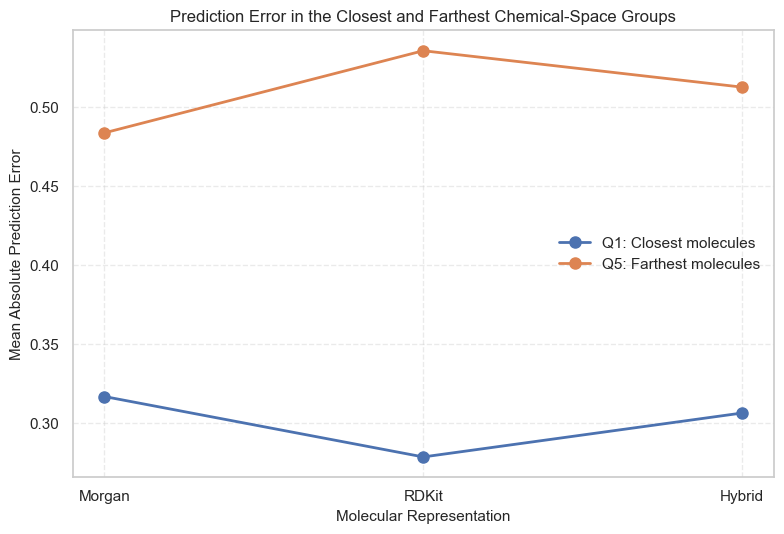

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("corrected_q1_q5_publication_stats.csv")

representations = ["Morgan", "RDKit", "Hybrid"]
data = data.set_index("Representation").reindex(representations)

plt.figure(figsize=(8, 5.5))

plt.plot(
    representations,
    data["Q1_mean_error"],
    marker="o",
    linewidth=2,
    markersize=8,
    label="Q1: Closest molecules"
)

plt.plot(
    representations,
    data["Q5_mean_error"],
    marker="o",
    linewidth=2,
    markersize=8,
    label="Q5: Farthest molecules"
)

plt.xlabel("Molecular Representation", fontsize=11)
plt.ylabel("Mean Absolute Prediction Error", fontsize=11)
plt.title(
    "Prediction Error in the Closest and Farthest Chemical-Space Groups",
    fontsize=12
)

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig(
    "Corrected_Figure3_Q1_Q5_Error_LinePlot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

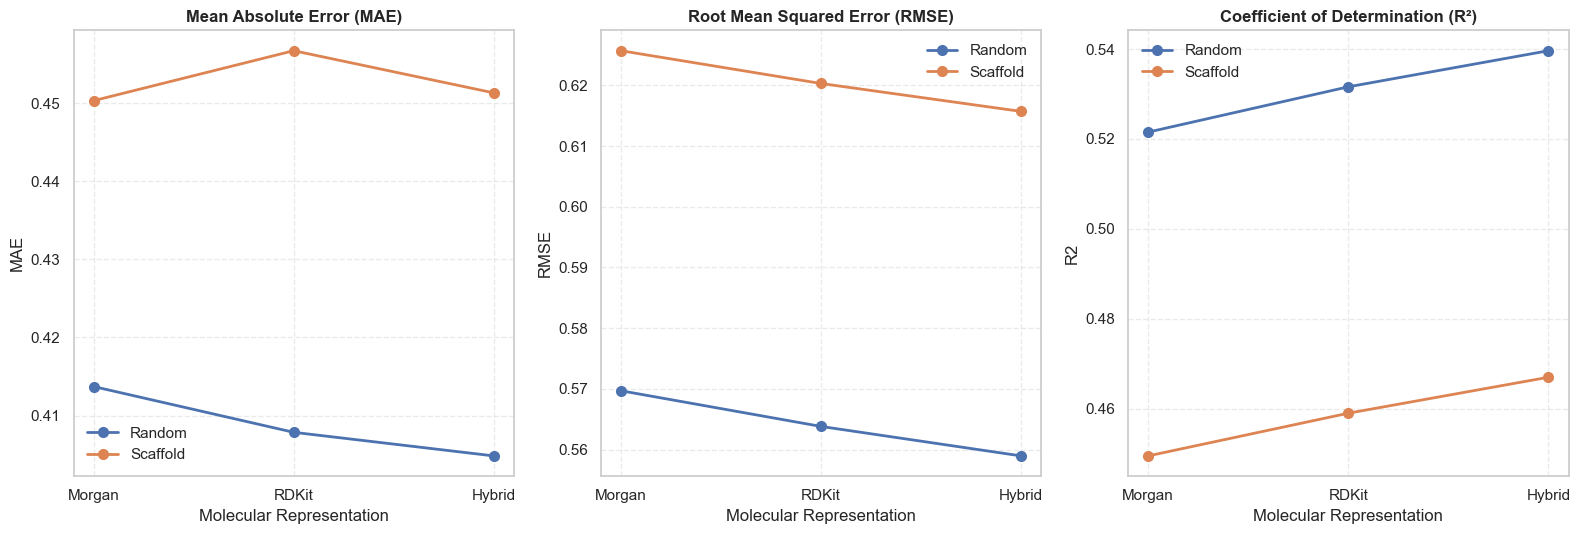

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Corrected random-split results
random_results = pd.read_csv(
    "Caco2_corrected_model_performance.csv"
)

# Existing scaffold-split results
scaffold_results = pd.read_csv(
    "scaffold_split_model_performance.csv"
)

random_results["Split"] = "Random"
scaffold_results["Split"] = "Scaffold"

combined = pd.concat(
    [random_results, scaffold_results],
    ignore_index=True
)

metrics = [
    ("MAE", "Mean Absolute Error (MAE)"),
    ("RMSE", "Root Mean Squared Error (RMSE)"),
    ("R2", "Coefficient of Determination (R²)")
]

representations = ["Morgan", "RDKit", "Hybrid"]
splits = ["Random", "Scaffold"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

for ax, (metric, title) in zip(axes, metrics):
    for split in splits:
        subset = combined[combined["Split"] == split]

        mean_values = (
            subset.groupby("Representation")[metric]
            .mean()
            .reindex(representations)
        )

        ax.plot(
            representations,
            mean_values,
            marker="o",
            linewidth=2,
            markersize=7,
            label=split
        )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Molecular Representation")
    ax.set_ylabel(metric)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    "Corrected_Figure4_Random_vs_Scaffold_LinePlots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Check the existing scaffold files

In [14]:
import os
import pandas as pd

files = [
    "scaffold_split_predictions.csv",
    "scaffold_predictions_with_training_distances.csv",
    "scaffold_training_distance_correlations_precise.csv",
    "scaffold_training_distance_q1q5.csv"
]

for file in files:
    print(f"\n{file}: {'FOUND' if os.path.exists(file) else 'MISSING'}")
    if os.path.exists(file):
        data = pd.read_csv(file)
        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())


scaffold_split_predictions.csv: FOUND
Shape: (4247, 10)
Columns: ['canonical_smiles', 'scaffold', 'log10_median_papp', 'y_true', 'Morgan_pred', 'Morgan_error', 'RDKit_pred', 'RDKit_error', 'Hybrid_pred', 'Hybrid_error']

scaffold_predictions_with_training_distances.csv: FOUND
Shape: (4247, 13)
Columns: ['canonical_smiles', 'scaffold', 'log10_median_papp', 'y_true', 'Morgan_pred', 'Morgan_error', 'RDKit_pred', 'RDKit_error', 'Hybrid_pred', 'Hybrid_error', 'Morgan_train_distance', 'RDKit_train_distance', 'Hybrid_train_distance']

scaffold_training_distance_correlations_precise.csv: FOUND
Shape: (3, 3)
Columns: ['Representation', 'Spearman_rho', 'p_value']

scaffold_training_distance_q1q5.csv: FOUND
Shape: (3, 8)
Columns: ['Representation', 'Q1_mean_error', 'Q5_mean_error', 'Increase_percent', 'U_statistic', 'p_value', 'p_holm', 'significant_after_holm']


# Verify the saved training distances

In [15]:
import pandas as pd
import numpy as np

data = pd.read_csv("scaffold_predictions_with_training_distances.csv")

distance_cols = [
    "Morgan_train_distance",
    "RDKit_train_distance",
    "Hybrid_train_distance"
]

print("Missing values:")
print(data[distance_cols].isna().sum())

print("\nDistance summary:")
display(data[distance_cols].describe())

print("\nPrediction rows:", len(data))
print("Unique scaffolds:", data["scaffold"].nunique())

Missing values:
Morgan_train_distance    0
RDKit_train_distance     0
Hybrid_train_distance    0
dtype: int64

Distance summary:


,Morgan_train_distance,RDKit_train_distance,Hybrid_train_distance
count,4247.000000,4247.000000,4247.000000
mean,0.353206,5.451408,0.839327
std,0.178117,3.087029,0.298377
min,0.000000,0.000000,0.000000
25%,0.226541,3.720296,0.635864
50%,0.324324,5.243604,0.824204
75%,0.471346,6.918448,1.045910
max,0.833333,71.684724,1.491658



Prediction rows: 4247
Unique scaffolds: 2139


In [16]:
import os

for file in os.listdir("."):
    if file.endswith(".ipynb") and "Scaffold" in file:
        print(file)

08_Scaffold-Based_Generalization_Analysis,.ipynb
08_Scaffold-Based_Generalization_Analysis_02.ipynb


# Create the corrected scaffold split

In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Use the existing dataset
y = df["log10_median_papp"].to_numpy()
groups = df["scaffold"].to_numpy()

# Reproducible scaffold split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx_scaffold, test_idx_scaffold = next(
    splitter.split(df, y, groups=groups)
)

train_scaffolds = set(groups[train_idx_scaffold])
test_scaffolds = set(groups[test_idx_scaffold])

print("Training molecules:", len(train_idx_scaffold))
print("Test molecules:", len(test_idx_scaffold))
print("Scaffold overlap:", len(train_scaffolds & test_scaffolds))

KeyError: 'scaffold'

In [18]:
print(df.columns.tolist())

['canonical_smiles', 'n_measurements', 'n_assays', 'min_papp', 'max_papp', 'median_papp', 'mean_papp', 'log10_range', 'log10_median_papp', 'mean_median_ratio', 'mol', 'rdkit_canonical_smiles', 'n_fragments', 'parent_mol', 'parent_smiles']


# Generate scaffold groups

In [19]:
from rdkit.Chem.Scaffolds import MurckoScaffold

# Generate a Bemis–Murcko scaffold for each molecule
df["scaffold"] = df["parent_smiles"].apply(
    lambda s: MurckoScaffold.MurckoScaffoldSmiles(
        smiles=s,
        includeChirality=False
    ) if pd.notna(s) else ""
)

print("Scaffold column created.")
print("Unique scaffolds:", df["scaffold"].nunique())
print("Missing scaffolds:", df["scaffold"].isna().sum())

Scaffold column created.
Unique scaffolds: 10406
Missing scaffolds: 0


# Create the corrected scaffold split

In [20]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

y = df["log10_median_papp"].to_numpy()
groups = df["scaffold"].to_numpy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(np.arange(len(df)), y, groups)
)

train_scaffolds = set(groups[train_idx])
test_scaffolds = set(groups[test_idx])

print("Training molecules:", len(train_idx))
print("Test molecules:", len(test_idx))
print("Training scaffolds:", len(train_scaffolds))
print("Test scaffolds:", len(test_scaffolds))
print("Overlapping scaffolds:", len(train_scaffolds & test_scaffolds))

Training molecules: 16551
Test molecules: 3898
Training scaffolds: 8324
Test scaffolds: 2082
Overlapping scaffolds: 0


In [22]:
import pickle

with open("caco2_morgan_chemical_space.pkl", "rb") as f:
    morgan_data = pickle.load(f)

print(morgan_data.keys())

dict_keys(['df_cs', 'X_morgan', 'nearest_indices', 'nearest_similarities', 'nearest_distances'])


# Prepare corrected molecular representations

In [23]:
from sklearn.preprocessing import StandardScaler, normalize
import numpy as np

# Target values
y = df["log10_median_papp"].to_numpy()

# 1. Morgan fingerprints
X_morgan = np.asarray(morgan_data["X_morgan"])

X_train_morgan = X_morgan[train_idx]
X_test_morgan = X_morgan[test_idx]

# 2. RDKit descriptors: fit scaler on training molecules only
X_rdkit_raw = np.asarray(rdkit_data["descriptors"])

scaler_scaffold_rdkit = StandardScaler()

X_train_rdkit = scaler_scaffold_rdkit.fit_transform(
    X_rdkit_raw[train_idx]
)
X_test_rdkit = scaler_scaffold_rdkit.transform(
    X_rdkit_raw[test_idx]
)

# 3. Hybrid representation
X_morgan_hybrid = np.asarray(hybrid_data["morgan_normalized"])

X_train_morgan_hybrid = normalize(X_morgan_hybrid[train_idx], norm="l2")
X_test_morgan_hybrid = normalize(X_morgan_hybrid[test_idx], norm="l2")

X_train_rdkit_hybrid = normalize(X_train_rdkit, norm="l2")
X_test_rdkit_hybrid = normalize(X_test_rdkit, norm="l2")

X_train_hybrid = np.hstack([
    X_train_morgan_hybrid,
    X_train_rdkit_hybrid
])

X_test_hybrid = np.hstack([
    X_test_morgan_hybrid,
    X_test_rdkit_hybrid
])

print("Morgan:", X_train_morgan.shape, X_test_morgan.shape)
print("RDKit:", X_train_rdkit.shape, X_test_rdkit.shape)
print("Hybrid:", X_train_hybrid.shape, X_test_hybrid.shape)

Morgan: (16551, 2048) (3898, 2048)
RDKit: (16551, 205) (3898, 205)
Hybrid: (16551, 2253) (3898, 2253)


# Train the corrected Random Forest models

In [24]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

representations = {
    "Morgan": (X_train_morgan, X_test_morgan),
    "RDKit": (X_train_rdkit, X_test_rdkit),
    "Hybrid": (X_train_hybrid, X_test_hybrid)
}

scaffold_results = []
scaffold_predictions = pd.DataFrame({
    "canonical_smiles": df.iloc[test_idx]["canonical_smiles"].to_numpy(),
    "scaffold": df.iloc[test_idx]["scaffold"].to_numpy(),
    "y_true": y[test_idx]
})

for name, (X_train, X_test) in representations.items():
    model = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y[train_idx])
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y[test_idx], predictions)
    rmse = np.sqrt(mean_squared_error(y[test_idx], predictions))
    r2 = r2_score(y[test_idx], predictions)

    scaffold_results.append({
        "Representation": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    scaffold_predictions[f"{name}_pred"] = predictions
    scaffold_predictions[f"{name}_error"] = np.abs(
        y[test_idx] - predictions
    )

    print(f"{name}: MAE={mae:.4f}, RMSE={rmse:.4f}, R²={r2:.4f}")

scaffold_results_df = pd.DataFrame(scaffold_results)
display(scaffold_results_df)

Morgan: MAE=0.4628, RMSE=0.6407, R²=0.3950
RDKit: MAE=0.4589, RMSE=0.6207, R²=0.4321
Hybrid: MAE=0.4532, RMSE=0.6143, R²=0.4438


,Representation,MAE,RMSE,R2
0,Morgan,0.462761,0.640693,0.395035
1,RDKit,0.458918,0.620746,0.432118
2,Hybrid,0.453214,0.614342,0.443775


# Calculate distance to the training chemical space

In [25]:
from sklearn.neighbors import NearestNeighbors
from rdkit import DataStructs

# 1. Morgan: distance = 1 - maximum Tanimoto similarity
morgan_fps = morgan_data["df_cs"]["morgan_fp"].tolist()

morgan_train_fps = [morgan_fps[i] for i in train_idx]
morgan_test_fps = [morgan_fps[i] for i in test_idx]

morgan_train_distance = []

for fp in morgan_test_fps:
    similarities = DataStructs.BulkTanimotoSimilarity(
        fp, morgan_train_fps
    )
    morgan_train_distance.append(1 - max(similarities))

morgan_train_distance = np.asarray(morgan_train_distance)

# 2. RDKit: nearest training molecule by Euclidean distance
nn_rdkit = NearestNeighbors(n_neighbors=1, metric="euclidean", n_jobs=-1)
nn_rdkit.fit(X_train_rdkit)
rdkit_train_distance = nn_rdkit.kneighbors(
    X_test_rdkit
)[0][:, 0]

# 3. Hybrid: nearest training molecule by Euclidean distance
nn_hybrid = NearestNeighbors(n_neighbors=1, metric="euclidean", n_jobs=-1)
nn_hybrid.fit(X_train_hybrid)
hybrid_train_distance = nn_hybrid.kneighbors(
    X_test_hybrid
)[0][:, 0]

scaffold_predictions["Morgan_train_distance"] = morgan_train_distance
scaffold_predictions["RDKit_train_distance"] = rdkit_train_distance
scaffold_predictions["Hybrid_train_distance"] = hybrid_train_distance

print("Test molecules:", len(scaffold_predictions))
print("Missing distances:",
      scaffold_predictions[
          ["Morgan_train_distance",
           "RDKit_train_distance",
           "Hybrid_train_distance"]
      ].isna().sum().to_dict())

display(scaffold_predictions.head())

Test molecules: 3898
Missing distances: {'Morgan_train_distance': 0, 'RDKit_train_distance': 0, 'Hybrid_train_distance': 0}


,canonical_smiles,scaffold,y_true,Morgan_pred,Morgan_error,RDKit_pred,RDKit_error,Hybrid_pred,Hybrid_error,Morgan_train_distance,RDKit_train_distance,Hybrid_train_distance
0,Brc1ccc(Cn2cc(CNC3CCCCCC3)nn2)cc1,c1ccc(Cn2cc(CNC3CCCCCC3)nn2)cc1,0.827369,1.005902,0.178533,1.194761,0.367391,1.183039,0.355670,0.423077,6.428997,1.120808
1,C#CCN(C)CCCCCCOc1ccc2c(c1)CCC2=O,O=C1CCc2ccccc21,1.108903,0.961299,0.147604,1.669922,0.561019,0.935431,0.173472,0.283019,4.284665,0.629569
2,C#CCN(C)CCCCCCOc1ccc2c(c1)CCCC2=O,O=C1CCCc2ccccc21,0.933487,0.969097,0.035610,1.722725,0.789238,0.926224,0.007264,0.309091,4.310037,0.661824
3,C#CCN(C)CCCCCOc1ccc2c(c1)CCC2=O,O=C1CCc2ccccc21,1.037825,0.961299,0.076525,1.167244,0.129420,0.944643,0.093181,0.283019,4.330002,0.626108
4,C#CCN(C)CCCCCOc1ccc2c(c1)CCCC2=O,O=C1CCCc2ccccc21,1.026533,0.969097,0.057436,1.135686,0.109153,0.941766,0.084767,0.309091,4.508897,0.659479


# Analyze distance versus prediction error

In [26]:
from scipy.stats import spearmanr

distance_columns = {
    "Morgan": "Morgan_train_distance",
    "RDKit": "RDKit_train_distance",
    "Hybrid": "Hybrid_train_distance"
}

error_columns = {
    "Morgan": "Morgan_error",
    "RDKit": "RDKit_error",
    "Hybrid": "Hybrid_error"
}

scaffold_distance_results = []

for representation in distance_columns:
    rho, p_value = spearmanr(
        scaffold_predictions[distance_columns[representation]],
        scaffold_predictions[error_columns[representation]]
    )

    scaffold_distance_results.append({
        "Representation": representation,
        "Spearman_rho": rho,
        "p_value": p_value
    })

scaffold_distance_results_df = pd.DataFrame(
    scaffold_distance_results
)

display(scaffold_distance_results_df)

,Representation,Spearman_rho,p_value
0,Morgan,0.182039,2.153326e-30
1,RDKit,0.215487,3.513956e-42
2,Hybrid,0.170296,9.424533e-27


# Compare Q1 versus Q5 prediction errors

In [27]:
from scipy.stats import mannwhitneyu

distance_columns = {
    "Morgan": "Morgan_train_distance",
    "RDKit": "RDKit_train_distance",
    "Hybrid": "Hybrid_train_distance"
}

error_columns = {
    "Morgan": "Morgan_error",
    "RDKit": "RDKit_error",
    "Hybrid": "Hybrid_error"
}

q1_q5_results = []

for rep in distance_columns:
    data = scaffold_predictions[
        [distance_columns[rep], error_columns[rep]]
    ].copy()

    data["distance_group"] = pd.qcut(
        data[distance_columns[rep]],
        q=5,
        labels=["Q1", "Q2", "Q3", "Q4", "Q5"],
        duplicates="drop"
    )

    q1 = data.loc[data["distance_group"] == "Q1", error_columns[rep]]
    q5 = data.loc[data["distance_group"] == "Q5", error_columns[rep]]

    u_stat, p_value = mannwhitneyu(
        q5, q1, alternative="two-sided"
    )

    q1_mean = q1.mean()
    q5_mean = q5.mean()

    q1_q5_results.append({
        "Representation": rep,
        "Q1_mean_error": q1_mean,
        "Q5_mean_error": q5_mean,
        "Increase_percent": (
            (q5_mean - q1_mean) / q1_mean * 100
            if q1_mean != 0 else np.nan
        ),
        "Q1_n": len(q1),
        "Q5_n": len(q5),
        "U_statistic": u_stat,
        "p_value": p_value
    })

scaffold_q1_q5_df = pd.DataFrame(q1_q5_results)
display(scaffold_q1_q5_df)

,Representation,Q1_mean_error,Q5_mean_error,Increase_percent,Q1_n,Q5_n,U_statistic,p_value
0,Morgan,0.373090,0.556451,49.146731,781,779,395944.0,6.173862e-25
1,RDKit,0.320146,0.564056,76.187068,780,780,412979.0,2.216586e-34
2,Hybrid,0.350173,0.524825,49.875987,780,780,386712.0,1.777922e-20


# Save the corrected scaffold results

In [29]:
import numpy as np
import pandas as pd

# Holm correction for the three Q1 vs Q5 p-values
p_values = scaffold_q1_q5_df["p_value"].to_numpy()
n = len(p_values)

order = np.argsort(p_values)
sorted_p = p_values[order]

adjusted_sorted = np.maximum.accumulate(
    (n - np.arange(n)) * sorted_p
)
adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

p_holm = np.empty(n)
p_holm[order] = adjusted_sorted

scaffold_q1_q5_df["p_holm"] = p_holm
scaffold_q1_q5_df["significant_after_holm"] = (
    scaffold_q1_q5_df["p_holm"] < 0.05
)

# Save all corrected scaffold outputs
scaffold_results_df.to_csv(
    "Caco2_corrected_scaffold_model_performance.csv", index=False
)

scaffold_predictions.to_csv(
    "Caco2_corrected_scaffold_predictions.csv", index=False
)

scaffold_distance_results_df.to_csv(
    "Caco2_corrected_scaffold_distance_correlations.csv", index=False
)

scaffold_q1_q5_df.to_csv(
    "Caco2_corrected_scaffold_Q1_Q5_results.csv", index=False
)

print("All four corrected scaffold CSV files saved.")
display(scaffold_q1_q5_df)

All four corrected scaffold CSV files saved.


,Representation,Q1_mean_error,Q5_mean_error,Increase_percent,Q1_n,Q5_n,U_statistic,p_value,p_holm,significant_after_holm
0,Morgan,0.373090,0.556451,49.146731,781,779,395944.0,6.173862e-25,1.234772e-24,True
1,RDKit,0.320146,0.564056,76.187068,780,780,412979.0,2.216586e-34,6.649758e-34,True
2,Hybrid,0.350173,0.524825,49.875987,780,780,386712.0,1.777922e-20,1.777922e-20,True


# Create the corrected scaffold performance line plot

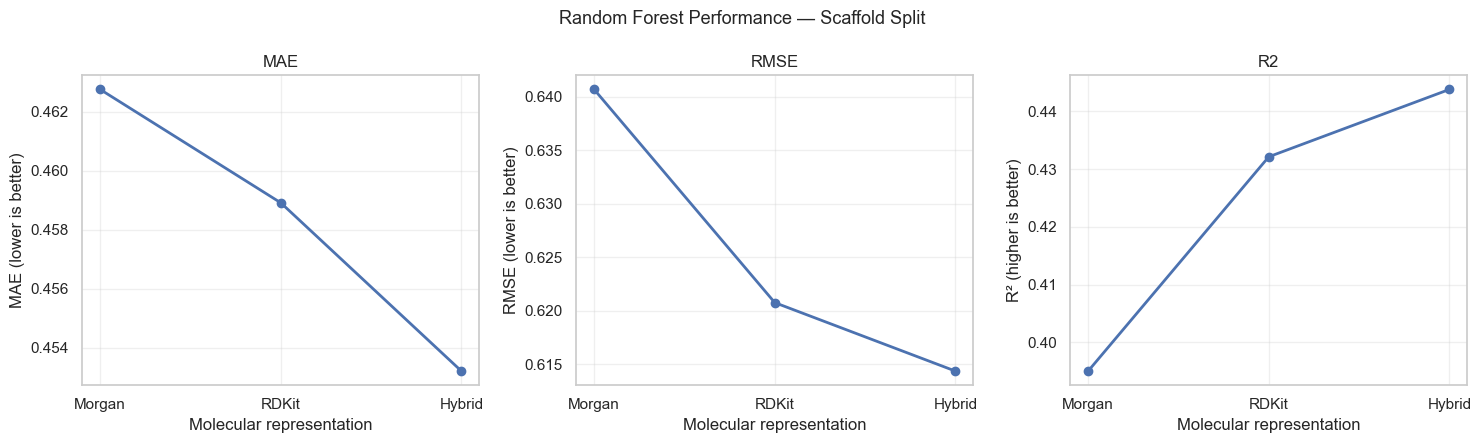

In [31]:
import matplotlib.pyplot as plt

plot_df = scaffold_results_df.set_index("Representation").loc[
    ["Morgan", "RDKit", "Hybrid"]
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metrics = [
    ("MAE", "MAE (lower is better)"),
    ("RMSE", "RMSE (lower is better)"),
    ("R2", "R² (higher is better)")
]

for ax, (metric, ylabel) in zip(axes, metrics):
    ax.plot(
        plot_df.index,
        plot_df[metric],
        marker="o",
        linewidth=2
    )
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Molecular representation")
    ax.set_title(metric)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Random Forest Performance — Scaffold Split",
    fontsize=13
)
plt.tight_layout()
plt.savefig(
    "Corrected_Figure1B_Scaffold_Performance_LinePlots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [32]:
plt.suptitle(
    "Random Forest Performance Across Molecular Representations "
    "Under Scaffold-Based Validation",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "Corrected_Figure1B_Scaffold_Performance_LinePlots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: Corrected_Figure1B_Scaffold_Performance_LinePlots.png")

<Figure size 640x480 with 0 Axes>

Saved: Corrected_Figure1B_Scaffold_Performance_LinePlots.png


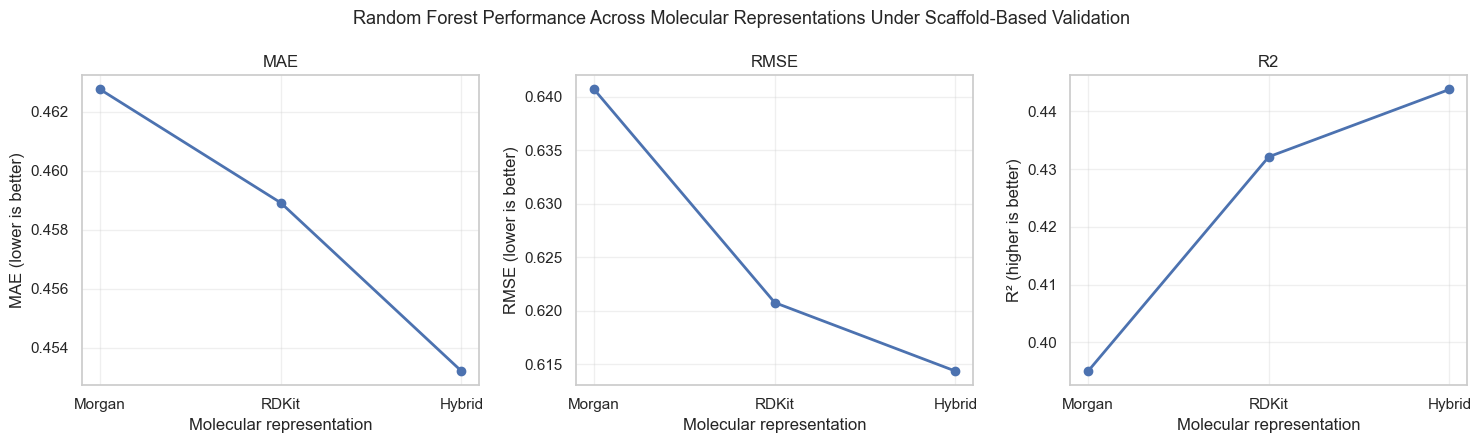

Corrected scaffold performance plot saved successfully.


In [33]:
import matplotlib.pyplot as plt

plot_df = scaffold_results_df.set_index("Representation").loc[
    ["Morgan", "RDKit", "Hybrid"]
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metrics = [
    ("MAE", "MAE (lower is better)"),
    ("RMSE", "RMSE (lower is better)"),
    ("R2", "R² (higher is better)")
]

for ax, (metric, ylabel) in zip(axes, metrics):
    ax.plot(plot_df.index, plot_df[metric], marker="o", linewidth=2)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Molecular representation")
    ax.set_title(metric)
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Random Forest Performance Across Molecular Representations "
    "Under Scaffold-Based Validation",
    fontsize=13
)

fig.tight_layout()

fig.savefig(
    "Corrected_Figure1B_Scaffold_Performance_LinePlots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Corrected scaffold performance plot saved successfully.")

# Corrected scaffold distance–error line plot

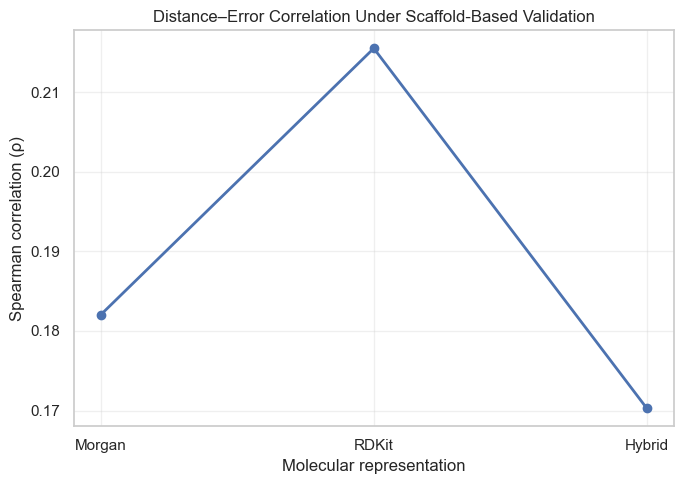

Corrected scaffold distance–error plot saved.


In [34]:
import matplotlib.pyplot as plt

plot_df = scaffold_distance_results_df.set_index(
    "Representation"
).loc[["Morgan", "RDKit", "Hybrid"]]

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    plot_df.index,
    plot_df["Spearman_rho"],
    marker="o",
    linewidth=2
)

ax.set_xlabel("Molecular representation")
ax.set_ylabel("Spearman correlation (ρ)")
ax.set_title("Distance–Error Correlation Under Scaffold-Based Validation")
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    "Corrected_Figure2B_Scaffold_Distance_Error_LinePlot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Corrected scaffold distance–error plot saved.")

# Save the corrected scaffold Q1–Q5 line plot

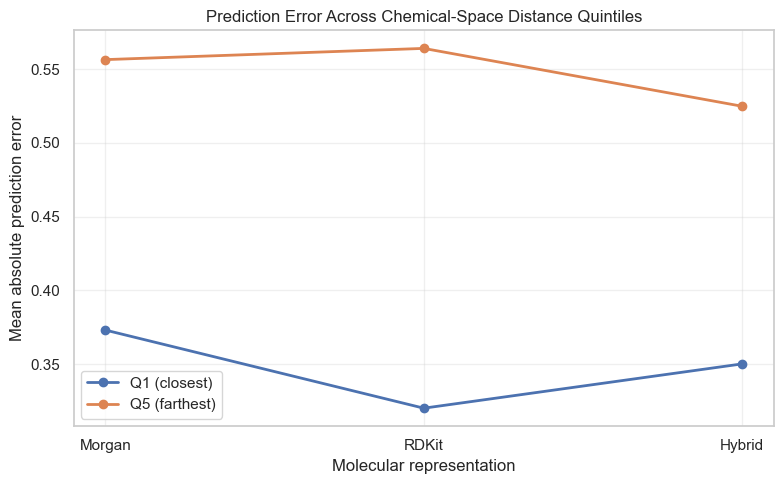

Corrected scaffold Q1–Q5 plot saved.


In [35]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = scaffold_q1_q5_df.set_index(
    "Representation"
).loc[["Morgan", "RDKit", "Hybrid"]]

x = np.arange(len(plot_df))
width = 0.18

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x, plot_df["Q1_mean_error"],
    marker="o", linewidth=2, label="Q1 (closest)"
)

ax.plot(
    x, plot_df["Q5_mean_error"],
    marker="o", linewidth=2, label="Q5 (farthest)"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df.index)
ax.set_xlabel("Molecular representation")
ax.set_ylabel("Mean absolute prediction error")
ax.set_title("Prediction Error Across Chemical-Space Distance Quintiles")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    "Corrected_Figure3B_Scaffold_Q1_Q5_LinePlot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Corrected scaffold Q1–Q5 plot saved.")

In [36]:
import pandas as pd

random_results = pd.read_csv(
    "Caco2_corrected_model_performance.csv"
)

scaffold_results = pd.read_csv(
    "Caco2_corrected_scaffold_model_performance.csv"
)

print("Random-split columns:")
print(random_results.columns.tolist())

print("\nScaffold-split columns:")
print(scaffold_results.columns.tolist())

display(random_results.head())
display(scaffold_results.head())

Random-split columns:
['Model', 'Representation', 'MAE', 'RMSE', 'R2']

Scaffold-split columns:
['Representation', 'MAE', 'RMSE', 'R2']


,Model,Representation,MAE,RMSE,R2
0,Random Forest,Morgan,0.385294,0.549837,0.554564
1,Random Forest,RDKit,0.404430,0.568149,0.524400
2,Random Forest,Hybrid,0.397954,0.559845,0.538202
3,XGBoost,Morgan,0.431430,0.582077,0.500796
4,XGBoost,RDKit,0.406337,0.556869,0.543099


,Representation,MAE,RMSE,R2
0,Morgan,0.462761,0.640693,0.395035
1,RDKit,0.458918,0.620746,0.432118
2,Hybrid,0.453214,0.614342,0.443775


# Create and save Corrected Figure 4

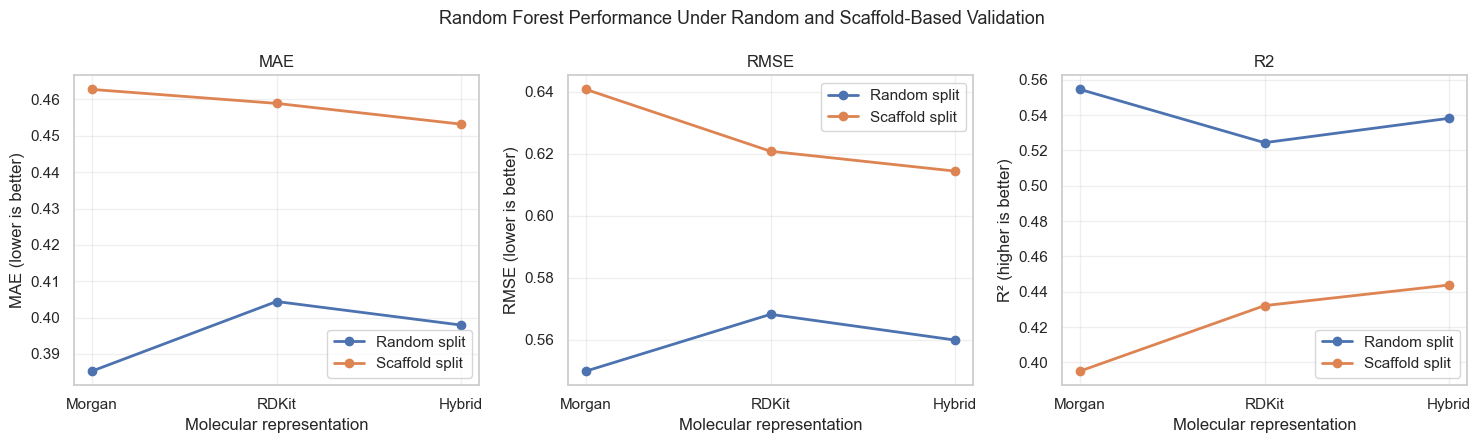

Corrected Figure 4 saved successfully.


In [37]:
import matplotlib.pyplot as plt
import pandas as pd

# Filter random-split results to Random Forest only
rf_random = random_results[
    random_results["Model"] == "Random Forest"
].set_index("Representation").loc[["Morgan", "RDKit", "Hybrid"]]

rf_scaffold = scaffold_results.set_index(
    "Representation"
).loc[["Morgan", "RDKit", "Hybrid"]]

representations = ["Morgan", "RDKit", "Hybrid"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metrics = [
    ("MAE", "MAE (lower is better)"),
    ("RMSE", "RMSE (lower is better)"),
    ("R2", "R² (higher is better)")
]

for ax, (metric, ylabel) in zip(axes, metrics):
    ax.plot(
        representations,
        rf_random.loc[representations, metric],
        marker="o",
        linewidth=2,
        label="Random split"
    )
    ax.plot(
        representations,
        rf_scaffold.loc[representations, metric],
        marker="o",
        linewidth=2,
        label="Scaffold split"
    )

    ax.set_title(metric)
    ax.set_xlabel("Molecular representation")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "Random Forest Performance Under Random and Scaffold-Based Validation",
    fontsize=13
)

fig.tight_layout()

fig.savefig(
    "Corrected_Figure4_Random_vs_Scaffold_LinePlots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Corrected Figure 4 saved successfully.")

# Create a corrected results summary

In [38]:
import pandas as pd

# Corrected random-split results: RF, XGBoost, LightGBM
random_results = pd.read_csv(
    "Caco2_corrected_model_performance.csv"
)

# Corrected scaffold-split results: Random Forest
scaffold_results = pd.read_csv(
    "Caco2_corrected_scaffold_model_performance.csv"
)

# Label the validation strategy
random_results["Validation"] = "Random split"
scaffold_results["Model"] = "Random Forest"
scaffold_results["Validation"] = "Scaffold split"

# Combine results without overwriting original files
corrected_summary = pd.concat(
    [random_results, scaffold_results],
    ignore_index=True
)

corrected_summary = corrected_summary[
    ["Validation", "Model", "Representation", "MAE", "RMSE", "R2"]
]

corrected_summary.to_csv(
    "Caco2_corrected_final_performance_summary.csv",
    index=False
)

display(corrected_summary)
print("Corrected performance summary saved.")

,Validation,Model,Representation,MAE,RMSE,R2
0,Random split,Random Forest,Morgan,0.385294,0.549837,0.554564
1,Random split,Random Forest,RDKit,0.404430,0.568149,0.524400
2,Random split,Random Forest,Hybrid,0.397954,0.559845,0.538202
3,Random split,XGBoost,Morgan,0.431430,0.582077,0.500796
4,Random split,XGBoost,RDKit,0.406337,0.556869,0.543099
5,Random split,XGBoost,Hybrid,0.415869,0.564645,0.530248
6,Random split,LightGBM,Morgan,0.424442,0.577169,0.509180
7,Random split,LightGBM,RDKit,0.412819,0.566428,0.527277
8,Random split,LightGBM,Hybrid,0.400701,0.552388,0.550422
9,Scaffold split,Random Forest,Morgan,0.462761,0.640693,0.395035


Corrected performance summary saved.


# Create the final results table

In [39]:
# Manuscript performance table
manuscript_results = corrected_summary.copy()

manuscript_results = manuscript_results[
    ["Validation", "Model", "Representation", "MAE", "RMSE", "R2"]
].copy()

manuscript_results[["MAE", "RMSE", "R2"]] = (
    manuscript_results[["MAE", "RMSE", "R2"]].round(4)
)

display(manuscript_results)

manuscript_results.to_csv(
    "Corrected_Manuscript_Model_Performance_Table.csv",
    index=False
)

print("Manuscript performance table saved.")

,Validation,Model,Representation,MAE,RMSE,R2
0,Random split,Random Forest,Morgan,0.3853,0.5498,0.5546
1,Random split,Random Forest,RDKit,0.4044,0.5681,0.5244
2,Random split,Random Forest,Hybrid,0.3980,0.5598,0.5382
3,Random split,XGBoost,Morgan,0.4314,0.5821,0.5008
4,Random split,XGBoost,RDKit,0.4063,0.5569,0.5431
5,Random split,XGBoost,Hybrid,0.4159,0.5646,0.5302
6,Random split,LightGBM,Morgan,0.4244,0.5772,0.5092
7,Random split,LightGBM,RDKit,0.4128,0.5664,0.5273
8,Random split,LightGBM,Hybrid,0.4007,0.5524,0.5504
9,Scaffold split,Random Forest,Morgan,0.4628,0.6407,0.3950


Manuscript performance table saved.


# Save a manuscript-formatted table

In [40]:
manuscript_results.to_excel(
    "Corrected_Manuscript_Model_Performance_Table.xlsx",
    index=False
)

print("Manuscript Excel table saved successfully.")

ModuleNotFoundError: No module named 'openpyxl'

In [41]:
import os
import pandas as pd

file_name = "Corrected_Manuscript_Model_Performance_Table.csv"

print("File exists:", os.path.exists(file_name))

check_table = pd.read_csv(file_name)
display(check_table.head())

File exists: True


,Validation,Model,Representation,MAE,RMSE,R2
0,Random split,Random Forest,Morgan,0.3853,0.5498,0.5546
1,Random split,Random Forest,RDKit,0.4044,0.5681,0.5244
2,Random split,Random Forest,Hybrid,0.3980,0.5598,0.5382
3,Random split,XGBoost,Morgan,0.4314,0.5821,0.5008
4,Random split,XGBoost,RDKit,0.4063,0.5569,0.5431


# prepare the distance–error correlation table

In [43]:
import os
import glob

for file in glob.glob("*distance*correlation*.csv"):
    print(file)

Caco2_corrected_scaffold_distance_correlations.csv
consolidated_distance_error_correlations.csv
corrected_distance_error_correlations.csv
scaffold_distance_error_correlations.csv
scaffold_training_distance_correlations.csv
scaffold_training_distance_correlations_precise.csv


# Load and save the manuscript table

In [44]:
import pandas as pd

correlation_file = "corrected_distance_error_correlations.csv"

distance_correlations = pd.read_csv(correlation_file)

display(distance_correlations)

distance_correlations.to_csv(
    "Corrected_Manuscript_Distance_Error_Correlations.csv",
    index=False
)

print("Manuscript distance-error correlation table saved.")

,Representation,Spearman_rho,Spearman_p_value
0,Morgan,0.196453,7.278465e-37
1,RDKit,0.265104,9.618917e-67
2,Hybrid,0.196295,8.311881e-37


Manuscript distance-error correlation table saved.


# save the corrected Q1–Q5 statistical results

In [45]:
import pandas as pd
import os

print("Q1-Q5 related files:")
for file in os.listdir():
    if "q1_q5" in file.lower() or "q1q5" in file.lower():
        print(file)

Q1-Q5 related files:
Caco2_corrected_scaffold_Q1_Q5_results.csv
corrected_distance_q1_q5_results.csv
Corrected_Figure3B_Scaffold_Q1_Q5_LinePlot.png
Corrected_Figure3_Q1_Q5_Error_LinePlot.png
corrected_q1_q5_publication_stats.csv
corrected_q1_q5_statistical_validation.csv
Figure3_Q1_Q5_error_comparison.png
Figure3_Q1_Q5_error_lineplot.png
scaffold_training_distance_q1q5.csv


In [46]:
import pandas as pd

q1q5_stats = pd.read_csv("corrected_q1_q5_publication_stats.csv")

display(q1q5_stats)

print("Columns:", q1q5_stats.columns.tolist())

,Representation,Q1_n,Q5_n,Q1_mean_error,Q5_mean_error,Error_increase_percent,Mann_Whitney_U,P_value,Rank_biserial,Rank_biserial_Q5_vs_Q1,P_value_scientific
0,Morgan,818,819,0.316897,0.483841,52.680682,235534.0,2.524872e-25,-0.296853,0.296853,2.525000e-25
1,RDKit,818,818,0.278634,0.535866,92.319322,204097.0,1.873837e-42,-0.389958,0.389958,1.874000e-42
2,Hybrid,818,818,0.306448,0.512804,67.337805,229550.0,4.207286e-28,-0.313879,0.313879,4.207000e-28


Columns: ['Representation', 'Q1_n', 'Q5_n', 'Q1_mean_error', 'Q5_mean_error', 'Error_increase_percent', 'Mann_Whitney_U', 'P_value', 'Rank_biserial', 'Rank_biserial_Q5_vs_Q1', 'P_value_scientific']


In [47]:
q1q5_stats.to_csv(
    "Corrected_Manuscript_Q1_Q5_Statistics.csv",
    index=False
)

print("Corrected manuscript Q1-Q5 statistics saved successfully.")

Corrected manuscript Q1-Q5 statistics saved successfully.


# verify the corrected scaffold-split Q1–Q5 results

In [48]:
scaffold_q1q5 = pd.read_csv(
    "Caco2_corrected_scaffold_Q1_Q5_results.csv"
)

display(scaffold_q1q5)
print("Columns:", scaffold_q1q5.columns.tolist())

,Representation,Q1_mean_error,Q5_mean_error,Increase_percent,Q1_n,Q5_n,U_statistic,p_value,p_holm,significant_after_holm
0,Morgan,0.373090,0.556451,49.146731,781,779,395944.0,6.173862e-25,1.234772e-24,True
1,RDKit,0.320146,0.564056,76.187068,780,780,412979.0,2.216586e-34,6.649758e-34,True
2,Hybrid,0.350173,0.524825,49.875987,780,780,386712.0,1.777922e-20,1.777922e-20,True


Columns: ['Representation', 'Q1_mean_error', 'Q5_mean_error', 'Increase_percent', 'Q1_n', 'Q5_n', 'U_statistic', 'p_value', 'p_holm', 'significant_after_holm']


# save a separate manuscript copy

In [49]:
scaffold_q1q5.to_csv(
    "Corrected_Manuscript_Scaffold_Q1_Q5_Statistics.csv",
    index=False
)

print("Corrected scaffold Q1-Q5 manuscript table saved.")

Corrected scaffold Q1-Q5 manuscript table saved.


#  verify the corrected scaffold model-performance results

In [50]:
import pandas as pd
import os

print("Scaffold performance files:")
for file in os.listdir():
    if "scaffold" in file.lower() and "performance" in file.lower():
        print(file)

Scaffold performance files:
Caco2_corrected_scaffold_model_performance.csv
Corrected_Figure1B_Scaffold_Performance_LinePlots.png
Figure1B_scaffold_split_performance.png
Figure4_random_vs_scaffold_performance.png
scaffold_split_model_performance.csv


In [51]:
scaffold_performance = pd.read_csv(
    "Caco2_corrected_scaffold_model_performance.csv"
)

display(scaffold_performance)
print("Columns:", scaffold_performance.columns.tolist())

,Representation,MAE,RMSE,R2
0,Morgan,0.462761,0.640693,0.395035
1,RDKit,0.458918,0.620746,0.432118
2,Hybrid,0.453214,0.614342,0.443775


Columns: ['Representation', 'MAE', 'RMSE', 'R2']


In [52]:
import pandas as pd

manuscript_results = pd.read_csv(
    "Corrected_Manuscript_Model_Performance_Table.csv"
)

display(manuscript_results)
print("Rows:", len(manuscript_results))
print("Columns:", manuscript_results.columns.tolist())

,Validation,Model,Representation,MAE,RMSE,R2
0,Random split,Random Forest,Morgan,0.3853,0.5498,0.5546
1,Random split,Random Forest,RDKit,0.4044,0.5681,0.5244
2,Random split,Random Forest,Hybrid,0.3980,0.5598,0.5382
3,Random split,XGBoost,Morgan,0.4314,0.5821,0.5008
4,Random split,XGBoost,RDKit,0.4063,0.5569,0.5431
5,Random split,XGBoost,Hybrid,0.4159,0.5646,0.5302
6,Random split,LightGBM,Morgan,0.4244,0.5772,0.5092
7,Random split,LightGBM,RDKit,0.4128,0.5664,0.5273
8,Random split,LightGBM,Hybrid,0.4007,0.5524,0.5504
9,Scaffold split,Random Forest,Morgan,0.4628,0.6407,0.3950


Rows: 12
Columns: ['Validation', 'Model', 'Representation', 'MAE', 'RMSE', 'R2']


In [53]:
manuscript_results_rounded = manuscript_results.copy()

for col in ["MAE", "RMSE", "R2"]:
    manuscript_results_rounded[col] = (
        manuscript_results_rounded[col].round(4)
    )

manuscript_results_rounded.to_csv(
    "Final_Manuscript_Model_Performance_Table.csv",
    index=False
)

print("Final manuscript performance table saved.")
display(manuscript_results_rounded)

Final manuscript performance table saved.


,Validation,Model,Representation,MAE,RMSE,R2
0,Random split,Random Forest,Morgan,0.3853,0.5498,0.5546
1,Random split,Random Forest,RDKit,0.4044,0.5681,0.5244
2,Random split,Random Forest,Hybrid,0.3980,0.5598,0.5382
3,Random split,XGBoost,Morgan,0.4314,0.5821,0.5008
4,Random split,XGBoost,RDKit,0.4063,0.5569,0.5431
5,Random split,XGBoost,Hybrid,0.4159,0.5646,0.5302
6,Random split,LightGBM,Morgan,0.4244,0.5772,0.5092
7,Random split,LightGBM,RDKit,0.4128,0.5664,0.5273
8,Random split,LightGBM,Hybrid,0.4007,0.5524,0.5504
9,Scaffold split,Random Forest,Morgan,0.4628,0.6407,0.3950


# Save the scaffold distance–error correlations

In [54]:
import pandas as pd

scaffold_correlations = pd.read_csv(
    "Caco2_corrected_scaffold_distance_correlations.csv"
)

display(scaffold_correlations)

scaffold_correlations.to_csv(
    "Corrected_Manuscript_Scaffold_Distance_Error_Correlations.csv",
    index=False
)

print("Corrected scaffold correlation table saved.")

,Representation,Spearman_rho,p_value
0,Morgan,0.182039,2.153326e-30
1,RDKit,0.215487,3.513956e-42
2,Hybrid,0.170296,9.424533e-27


Corrected scaffold correlation table saved.


In [55]:
import os

figure_files = [
    "Corrected_Figure1A_Random_Split_Performance_LinePlots.png",
    "Corrected_Figure1B_Scaffold_Performance_LinePlots.png",
    "Corrected_Figure2_Distance_Error_Correlation_LinePlot.png",
    "Corrected_Figure3_Q1_Q5_Error_LinePlot.png",
    "Corrected_Figure3B_Scaffold_Q1_Q5_LinePlot.png",
    "Corrected_Figure4_Random_vs_Scaffold_LinePlots.png"
]

for file in figure_files:
    print(f"{file}: {'FOUND' if os.path.exists(file) else 'MISSING'}")

Corrected_Figure1A_Random_Split_Performance_LinePlots.png: FOUND
Corrected_Figure1B_Scaffold_Performance_LinePlots.png: FOUND
Corrected_Figure2_Distance_Error_Correlation_LinePlot.png: FOUND
Corrected_Figure3_Q1_Q5_Error_LinePlot.png: FOUND
Corrected_Figure3B_Scaffold_Q1_Q5_LinePlot.png: FOUND
Corrected_Figure4_Random_vs_Scaffold_LinePlots.png: FOUND


# create a manuscript-results folder

In [56]:
import os
import shutil

output_folder = "JCIM_Manuscript_Results"
os.makedirs(output_folder, exist_ok=True)

files_to_copy = [
    "Corrected_Figure1A_Random_Split_Performance_LinePlots.png",
    "Corrected_Figure1B_Scaffold_Performance_LinePlots.png",
    "Corrected_Figure2_Distance_Error_Correlation_LinePlot.png",
    "Corrected_Figure3_Q1_Q5_Error_LinePlot.png",
    "Corrected_Figure3B_Scaffold_Q1_Q5_LinePlot.png",
    "Corrected_Figure4_Random_vs_Scaffold_LinePlots.png",
    "Final_Manuscript_Model_Performance_Table.csv",
    "Corrected_Manuscript_Distance_Error_Correlations.csv",
    "Corrected_Manuscript_Scaffold_Distance_Error_Correlations.csv",
    "Corrected_Manuscript_Q1_Q5_Statistics.csv",
    "Corrected_Manuscript_Scaffold_Q1_Q5_Statistics.csv"
]

for file in files_to_copy:
    if os.path.exists(file):
        shutil.copy2(file, output_folder)
        print("Copied:", file)
    else:
        print("MISSING:", file)

print("\nManuscript results folder:", os.path.abspath(output_folder))

Copied: Corrected_Figure1A_Random_Split_Performance_LinePlots.png
Copied: Corrected_Figure1B_Scaffold_Performance_LinePlots.png
Copied: Corrected_Figure2_Distance_Error_Correlation_LinePlot.png
Copied: Corrected_Figure3_Q1_Q5_Error_LinePlot.png
Copied: Corrected_Figure3B_Scaffold_Q1_Q5_LinePlot.png
Copied: Corrected_Figure4_Random_vs_Scaffold_LinePlots.png
Copied: Final_Manuscript_Model_Performance_Table.csv
Copied: Corrected_Manuscript_Distance_Error_Correlations.csv
Copied: Corrected_Manuscript_Scaffold_Distance_Error_Correlations.csv
Copied: Corrected_Manuscript_Q1_Q5_Statistics.csv
Copied: Corrected_Manuscript_Scaffold_Q1_Q5_Statistics.csv

Manuscript results folder: C:\Users\kiran\Cheminformatics_course\Paper\JCIM_Manuscript_Results


In [57]:
import sys
import platform
import numpy as np
import pandas as pd
import sklearn
import rdkit
import xgboost
import lightgbm
import scipy
import matplotlib

print("=== Software Versions for Manuscript ===")
print(f"Python       : {sys.version.split()[0]}")
print(f"Platform     : {platform.platform()}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"RDKit        : {rdkit.__version__}")
print(f"XGBoost      : {xgboost.__version__}")
print(f"LightGBM     : {lightgbm.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

=== Software Versions for Manuscript ===
Python       : 3.10.18
Platform     : Windows-10-10.0.26200-SP0
NumPy        : 1.26.4
Pandas       : 2.3.3
scikit-learn : 1.7.2
RDKit        : 2025.09.1
XGBoost      : 3.0.5
LightGBM     : 4.6.0
SciPy        : 1.10.1
Matplotlib   : 3.10.6
